In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, stats, chi2_contingency, chi2
import statsmodels.api as sm
from statsmodels.tools.tools import add_constant
from sklearn.feature_selection import RFE, SelectKBest, f_regression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score, RandomizedSearchCV

from sklearn.experimental import enable_iterative_imputer
import miceforest as mf
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

from sklearn.linear_model import LogisticRegression, BayesianRidge
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, fbeta_score, average_precision_score, roc_auc_score, precision_recall_curve, brier_score_loss
from imblearn.metrics import geometric_mean_score
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.calibration import calibration_curve, CalibrationDisplay
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference, equalized_odds_ratio, true_positive_rate, false_positive_rate
import shap

import psutil
import time, threading, os

Kaggle Dataset: [ECommerce Customer Behaviour Dataset](https://www.kaggle.com/datasets/dhairyajeetsingh/ecommerce-customer-behavior-dataset)

In [66]:
df = pd.read_csv("C:\GitHub\A Bunch of Datasets\ecommerce_customer_churn_dataset.csv")
pd.set_option("display.max_columns", None)

In [67]:
sns.set_theme(style="ticks", palette="flare")
palette = sns.color_palette("flare", 6)
palette2 = sns.color_palette("crest", 6)
churn_colours = [palette2[1], palette[4]]

---
# 1. DATASET OVERVIEW
Preliminary portion of EDA in which action will be taken to correct flaws in the data (all but imputation)

In [68]:
print(f"Dataset Size: {df.shape[0]} rows and {df.shape[1]} columns")
print(f"Duplicated present? {df.duplicated().any()}")

Dataset Size: 50000 rows and 25 columns
Duplicated present? False


## 1.1 Descriptive Statistics
These values will be referenced throughout the EDA

In [36]:
df.describe()

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.000000,50000.000000,50000.000000,46601.000000,47000.000000,50000.000000,46000.000000,50000.000000,50000.000000,47000.000000,46500.000000,45509.000000,47472.000000,49832.000000,46500.000000,44000.000000,45000.000000,47500.000000,50000.000000,44500.000000,50000.000000
mean,37.802968,2.984009,11.624660,27.660754,8.737811,57.079973,4.298391,13.111576,123.117330,29.792872,41.997485,6.680913,20.937980,5.681831,2.853312,29.364466,19.371607,2.353874,1440.626292,1966.233258,0.289000
std,11.834668,2.059105,7.810657,10.871013,3.778220,16.282723,3.189754,7.017312,175.569714,29.695062,21.373642,6.143027,14.252561,2.676052,2.328948,20.574021,9.419252,1.110012,907.249443,1225.072166,0.453302
min,5.000000,0.100000,0.000000,1.000000,1.000000,0.000000,0.000000,-13.000000,26.380000,0.000000,0.240000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,29.000000,1.400000,6.000000,19.700000,6.000000,46.400000,2.000000,8.000000,87.050000,9.000000,25.300000,2.900000,9.900000,4.000000,1.000000,13.200000,12.500000,2.000000,789.817500,1049.000000,0.000000
50%,38.000000,2.500000,11.000000,26.800000,8.400000,58.100000,4.000000,12.000000,112.970000,21.000000,40.200000,5.400000,19.700000,5.000000,2.000000,27.600000,18.600000,2.000000,1243.415000,1896.000000,0.000000
75%,46.000000,4.000000,17.000000,34.700000,11.200000,68.700000,6.000000,17.000000,144.440000,41.000000,57.000000,9.100000,30.400000,7.000000,4.000000,43.100000,25.500000,3.000000,1874.000000,2791.000000,1.000000
max,200.000000,10.000000,46.000000,75.600000,24.100000,143.743350,28.000000,128.700000,9666.379178,287.000000,116.640000,99.615734,91.700000,21.000000,21.000000,100.000000,61.900000,5.000000,8987.240000,7197.000000,1.000000


## 1.2 Missing Values
If a row or column has too many missing values it would be better to drop them rather than impute them - poor representation would lead to bias and false patterns.

In [69]:
null_cols = pd.DataFrame({
    "Null Count": df.isnull().sum(),
    "Null Percentage": (df.isnull().sum() / len(df)) * 100
})
# get columns that have nulls
null_cols = null_cols[null_cols["Null Count"] > 0]
null_cols = null_cols.sort_values(by="Null Percentage", ascending=False)
null_cols

,Null Count,Null Percentage
Social_Media_Engagement_Score,6000,12.000
Credit_Balance,5500,11.000
Mobile_App_Usage,5000,10.000
Returns_Rate,4491,8.982
Wishlist_Items,4000,8.000
Discount_Usage_Rate,3500,7.000
Product_Reviews_Written,3500,7.000
Session_Duration_Avg,3399,6.798
Pages_Per_Session,3000,6.000
Days_Since_Last_Purchase,3000,6.000


### 1.2.1 Null Analysis on Churn Rate
To see whether missingness has any significant relation to churn and whether its meaningful to classification (these are percentages)\
There is no noticable pattern or difference between churners and non-churners -> comfirms very little association between missingess and churn

*Positive difference* indicates that the missing group has a higher churn rate while \
a *negative difference* indicates that the missing group has a higher churn rate

In [73]:
missing_columns = null_cols.index.tolist() 
results = []
for col in missing_columns:
    missing = df[df[col].isna()]
    present = df[df[col].notna()] # non missing

    results.append({
        "Feature": col,
        "Missing Churn Rate (%)": missing["Churned"].mean() * 100, 
        "Non-Missing Churn Rate (%)": present["Churned"].mean() * 100, 
        "Difference": (missing["Churned"].mean() - present["Churned"].mean()) * 100
    })
# Positive difference -> missing group has higher churn rate
# Negative difference -> missing group has lower churn rate
# close to 0 -> missingness may not have a meaningful relationship with churn
df_missing_analysis = pd.DataFrame(results)
df_missing_analysis

,Feature,Missing Churn Rate (%),Non-Missing Churn Rate (%),Difference
0,Social_Media_Engagement_Score,29.683333,28.793182,0.890152
1,Credit_Balance,29.454545,28.831461,0.623085
2,Mobile_App_Usage,28.740000,28.917778,-0.177778
3,Returns_Rate,29.881986,28.803094,1.078892
4,Wishlist_Items,28.950000,28.895652,0.054348
5,Discount_Usage_Rate,26.285714,29.096774,-2.811060
6,Product_Reviews_Written,30.028571,28.815054,1.213518
7,Session_Duration_Avg,41.129744,28.007983,13.121761
8,Pages_Per_Session,27.933333,28.961702,-1.028369
9,Days_Since_Last_Purchase,29.466667,28.863830,0.602837


There are some customers with Total_Purchases = 0, but they clearly have purhasing activity ->  average order value and days since last purchase have a value. which means that total_purchase value is erroneous

In [74]:
missing_tp = df[df["Total_Purchases"] == 0]
missing_tp

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
2198,30.0,Female,France,Lyon,2.9,1.0,18.1,1.1,75.3,2.0,0.0,68.26,28.0,75.24,4.4,0.7,7.0,0.0,0.0,3.3,4.0,0.0,1497.0,1,Q4
15196,43.0,Female,USA,Chicago,7.2,0.0,11.1,4.1,71.1,0.0,0.0,78.67,2.0,23.40,4.0,25.5,9.0,0.0,0.0,11.6,2.0,0.0,2770.0,0,Q3
15794,34.0,Male,UK,Leeds,4.5,8.0,NaN,4.3,81.1,0.0,0.0,194.75,13.0,49.70,15.2,8.9,7.0,0.0,0.0,2.8,1.0,0.0,1306.0,1,Q3
23747,NaN,Female,Japan,Nagoya,5.0,2.0,14.9,2.0,65.7,0.0,0.0,139.90,21.0,3.30,6.2,0.0,8.0,1.0,NaN,12.4,1.0,0.0,0.0,1,Q1
31584,31.0,Female,Canada,Montreal,6.5,10.0,NaN,1.0,76.1,0.0,0.0,58.74,1.0,64.44,11.3,2.9,9.0,0.0,14.6,0.0,2.0,0.0,0.0,1,Q4
32581,33.0,Female,UK,London,1.8,2.0,9.8,2.6,89.6,0.0,0.0,62.45,23.0,NaN,2.2,0.0,7.0,0.0,0.0,9.4,1.0,0.0,0.0,1,Q3
33939,37.0,Male,Canada,Montreal,1.8,8.0,5.8,NaN,78.0,0.0,0.0,46.65,0.0,17.50,12.8,14.0,10.0,0.0,NaN,NaN,3.0,0.0,1195.0,1,Q3
38702,33.0,Male,Japan,Yokohama,0.8,0.0,8.9,3.0,92.3,NaN,0.0,101.66,10.0,28.50,NaN,NaN,8.0,0.0,14.7,14.0,3.0,0.0,1785.0,1,Q3
40098,25.0,Male,Canada,Montreal,5.5,0.0,9.4,4.1,73.4,0.0,0.0,124.49,20.0,NaN,1.2,2.7,10.0,0.0,0.0,9.7,1.0,0.0,798.0,1,Q4


---
# 2. DATA CLEANING

## 2.1 Convert Currencies to USD
There are 8 different countries and 8 different currencies. Since the majority of the customers are from the USA, all other currencies will be converted to USD.\
**Conversion rate on *23/07/2026***

In [76]:
exchange_rates = {"USA": 1, "UK": 1.33, "Canada": 0.71, "Germany": 1.14,
    "Australia": 0.70, "France": 1.14, "India": 0.01,"Japan": 0.01
}

monetary_cols = ["Average_Order_Value", "Lifetime_Value", "Credit_Balance"]

for col in monetary_cols:
    df[col] = df[col] * df["Country"].map(exchange_rates)

## 2.2 Convert Discrete Values Into Integers
Features like age, total purchases and login frequency were stored as floats even though they are discrete values. These were converted to ensure the data type matches the meaning of the variable (it also reduces memory use).\
(Used Int64 because there are null values)

In [77]:
## Convert to Integer because these are discrete variables
int_cols = ["Age", "Login_Frequency", "Total_Purchases", "Days_Since_Last_Purchase",
            "Customer_Service_Calls", "Product_Reviews_Written", "Payment_Method_Diversity", "Wishlist_Items"]
df[int_cols] = df[int_cols].round().astype("Int64") #Int64 nullable

## 2.3 Standardising & Correcting Inconsistencies

### 2.3.1 Standardise Discount_Usage_Rate
The [descriptive statistics](#1.1-Descriptive-Statistics) showed that the minimum discount usage rate is 0.24 and the maximum is 116.62. These fall out of the expected 0-100 range expected of a percentage. 

In [78]:
print("Num discount usage OVER 100 = ", len(df[df["Discount_Usage_Rate"] > 100]), "| Num discount usage UNDER 1 = ", len(df[df["Discount_Usage_Rate"] < 1]))

Num discount usage OVER 100 =  207 | Num discount usage UNDER 1 =  21


#### Cap discounts at 100 & set discounts below 1 to zero
- Values above 100 are not possible. Since there is no context behind the error, these instances will be corrected by **capping them at 100**
- There is the possibility that the values (0, 1) were erroneously recorded as proportions instead of percentages. However, it is not unrealistic that there are no customers that have not used discounts (recall min was 0.24) and there are no 0 values here. So, under this assumption, they will be **set to 0**. 

In [79]:
# set values over 100 to 100
print("Maximum before correction:", df["Discount_Usage_Rate"].max())
df.loc[df["Discount_Usage_Rate"] > 100, "Discount_Usage_Rate"] = 100
print("Maximum after Correction", df["Discount_Usage_Rate"].max())

Maximum before correction: 116.64
Maximum after Correction 100.0


In [80]:
print("Minimum before correction:", df["Discount_Usage_Rate"].min())

df.loc[df["Discount_Usage_Rate"] < 1, "Discount_Usage_Rate"] = 0
print("Minimum after correction:", df["Discount_Usage_Rate"].min())

Minimum before correction: 0.24
Minimum after correction: 0.0


### 2.3.2 Total_Purchases & Lifetime_Value Inconsistencies

In [81]:
print(f"0 Total Purchases Count: {len(df[df["Total_Purchases"] == 0])} (and 0 Lifetime Value Count {len(df[df["Lifetime_Value"] == 0])})")
print("Negative Total Purchases Count: ", len(df[df["Total_Purchases"] < 0]))

0 Total Purchases Count: 9 (and 0 Lifetime Value Count 9)
Negative Total Purchases Count:  40


#### Negative Total Purchase Count
The [descriptive statistics](#1.1-Descriptive-Statistics) showed that the minimum value for total purchases is a negative number, which is obviously incorrect. This will be corrected by **setting purchases column to absolute value**

In [82]:
print("Minimum before correction:", df["Total_Purchases"].min())
df["Total_Purchases"] = df["Total_Purchases"].abs()
print("Minimum after correction:", df["Total_Purchases"].min())

Minimum before correction: -13
Minimum after correction: 0


#### Zero Total_Purchases with Purchase Activity
The Total_Purchases and Lifetime_Value for the 9 records is 0, however, the other records show that they have actually made purchases (average order value, return rate, days since last purchase etc are all non-zero).
(Interesting to note that this profile paints a picture of customer dissatisfaction.)

In [83]:
zero_purchases = df[df["Total_Purchases"] == 0]
zero_purchases

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
2198,30,Female,France,Lyon,2.9,1,18.1,1.1,75.3,2,0,77.8164,28,75.24,4.4,0.7,7,0,0.0,3.3,4,0.0,1706.58,1,Q4
15196,43,Female,USA,Chicago,7.2,0,11.1,4.1,71.1,0,0,78.6700,2,23.40,4.0,25.5,9,0,0.0,11.6,2,0.0,2770.00,0,Q3
15794,34,Male,UK,Leeds,4.5,8,NaN,4.3,81.1,0,0,259.0175,13,49.70,15.2,8.9,7,0,0.0,2.8,1,0.0,1736.98,1,Q3
23747,<NA>,Female,Japan,Nagoya,5.0,2,14.9,2.0,65.7,0,0,1.3990,21,3.30,6.2,0.0,8,1,NaN,12.4,1,0.0,0.00,1,Q1
31584,31,Female,Canada,Montreal,6.5,10,NaN,1.0,76.1,0,0,41.7054,1,64.44,11.3,2.9,9,0,14.6,0.0,2,0.0,0.00,1,Q4
32581,33,Female,UK,London,1.8,2,9.8,2.6,89.6,0,0,83.0585,23,NaN,2.2,0.0,7,0,0.0,9.4,1,0.0,0.00,1,Q3
33939,37,Male,Canada,Montreal,1.8,8,5.8,NaN,78.0,0,0,33.1215,0,17.50,12.8,14.0,10,0,NaN,NaN,3,0.0,848.45,1,Q3
38702,33,Male,Japan,Yokohama,0.8,0,8.9,3.0,92.3,<NA>,0,1.0166,10,28.50,NaN,NaN,8,0,14.7,14.0,3,0.0,17.85,1,Q3
40098,25,Male,Canada,Montreal,5.5,0,9.4,4.1,73.4,0,0,88.3879,20,NaN,1.2,2.7,10,0,0.0,9.7,1,0.0,566.58,1,Q4


**Set 0 Total Purchase and 0 Lifetime Value to NaN**

In [84]:
# set to nan
df.loc[(df["Total_Purchases"] == 0), "Total_Purchases"] = np.nan
print("Number of zero Total Purchases records after correction: ", len(df[df["Total_Purchases"] == 0]))
df.loc[(df["Lifetime_Value"] == 0), "Lifetime_Value"] = np.nan
print("Number of zero Lifetime Value records after correction: ", len(df[df["Total_Purchases"] == 0]))

Number of zero Total Purchases records after correction:  0
Number of zero Lifetime Value records after correction:  0


### 2.3.3 Correcting Age Outliers
The [descriptive statistics](#1.1-Descriptive-Statistics) showed that the minimum age is 5 the maximum age is 200. These are both unrealistic and unreasonable.

In [85]:
age_analysis = pd.DataFrame({
    "Age Group": ["Under 13", "14-17", "18-59", "60-75", "76-100", "Over 100"],
    "Count":[
        (df["Age"] < 12).sum(), 
        ((df["Age"] >= 12) & (df["Age"] <= 17)).sum(),
        ((df["Age"] >= 18) & (df["Age"] <= 59)).sum(), 
        ((df["Age"] >= 60) & (df["Age"] <= 75)).sum(), 
        ((df["Age"] >= 76) & (df["Age"] <= 100)).sum(),
        (df["Age"] > 75).sum()
    ]
})
age_analysis

,Age Group,Count
0,Under 13,30
1,14-17,0
2,18-59,45883
3,60-75,1572
4,76-100,0
5,Over 100,20


Seeing as "teenagers" as a whole are not represented at all in this dataset, it is improbable that children would be represented, these values are thus considered impossible. **Ages <= 17 will be set to null and imputed later**

There are no records with ages from 76 to 100. Therefore, the actual max age without the large outliers is 75.\ 
Ages over 100, while not technically impossible, are contextually unrealistic and will therefore be **set to null and imputed later as well**

In [86]:
print("Num null ages before setting NaN: ", df["Age"].isna().sum())
# set values lesser than 18 to NaN | set values greater than 75 to NaN
df.loc[(df["Age"] < 18) | (df["Age"] > 75), "Age"] = np.nan
print("Num null ages  after setting NaN: ", df["Age"].isna().sum())

Num null ages before setting NaN:  2495
Num null ages  after setting NaN:  2545


---
# 3. EXPLORATORY DATA ANALYSIS

In [87]:
features = df.drop("Churned", axis=1)

cat_features = features.select_dtypes(include="object").columns
num_features = features.select_dtypes(exclude="object").columns

## 3.1 Univariate Analysis
Analysis of distributions of individual features

### 3.1.1 Churn Class Distribution
About a third of customers in this dataset are churners:\
**35 542 non-churners | 14 466 churners**

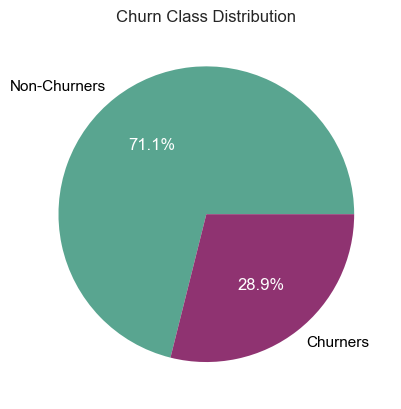

In [88]:
wedges, texts, autotexts = plt.pie(
    df["Churned"].value_counts(), labels=["Non-Churners", "Churners"], autopct="%1.1f%%", colors=churn_colours, textprops={"color": "black"}, wedgeprops={"linewidth": 0})
plt.setp(autotexts, color="white")
plt.title("Churn Class Distribution")
plt.show()

### 3.1.2 Distribution of Categorical Features
Count plot shows the number of customers in each category of the given feature.

- Gender: there are slightly more males than females, the third option, "other" is expectedly a minority
- Country: the majority of customers are from the USA and western countries in general
- City: naturally, american cities are the most frequently occuring
- Signup Quarter has a fairly even spread

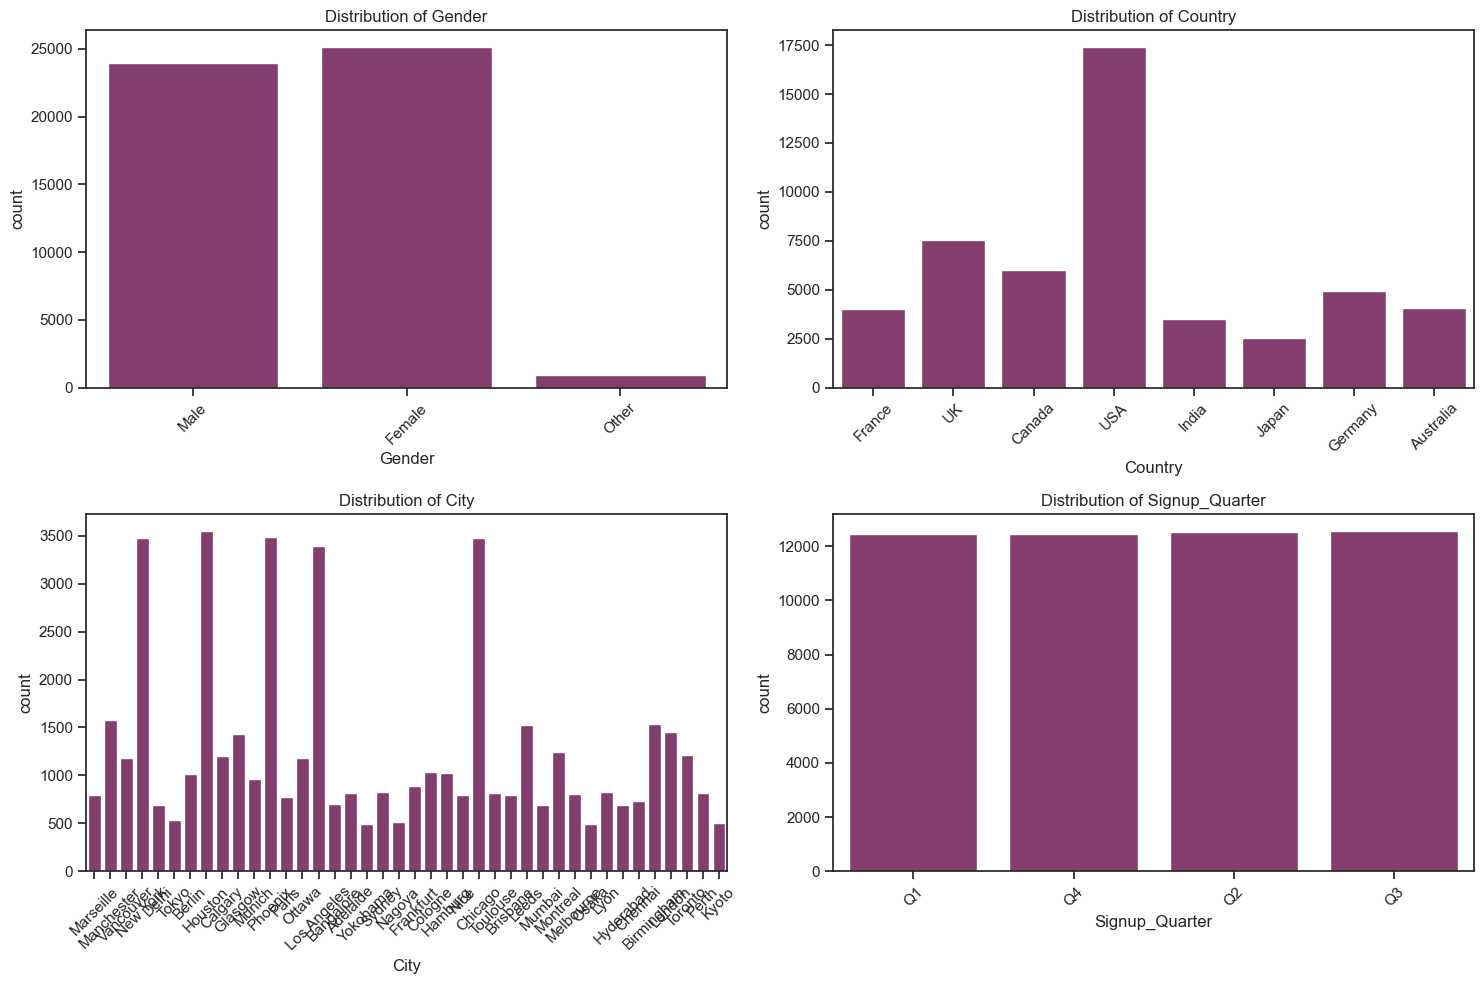

In [89]:
# plot categorical feature distributions with bar graph
fig, axes = plt.subplots(2,2, figsize=(15, 10))
axes = axes.flatten()

for i, feature in enumerate(cat_features):
    sns.countplot(data=df, x=feature, ax=axes[i], color=palette[4])
    axes[i].set_title(f"Distribution of {feature}")
    axes[i].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 3.1.2 Distribution of Numerical Features
There is skewness evident in most of the features but age, session duration avg, pages per session, discount usage and cart abandonment rate all seem fairly symmentric.

In [91]:
# get skewness of all numerical fields
skew_summary = pd.DataFrame({ "Feature": num_features, "Skewness": [skew(df[col].dropna()) for col in num_features]})

In [92]:
# https://www.geeksforgeeks.org/python/pandas-cut-method-in-python/
# (positive = right skew | negative = left skew | 0 = symmetric)
labels = ["Heavily Left Skewed", "Moderately Left Skewed", "Approximately Symmetric",
         "Moderately Right Skewed", "Heavily Right Skewed"]
bins = [-np.inf, -1, -0.5, 0.5, 1, np.inf]

skew_summary["Interpretation"] = pd.cut(
    skew_summary["Skewness"], bins=bins, labels=labels)
skew_summary.sort_values(by="Skewness", key=abs, ascending=False)

,Feature,Skewness,Interpretation
8,Average_Order_Value,42.354227,Heavily Right Skewed
11,Returns_Rate,5.880519,Heavily Right Skewed
7,Total_Purchases,2.714663,Heavily Right Skewed
9,Days_Since_Last_Purchase,1.991053,Heavily Right Skewed
18,Lifetime_Value,1.400898,Heavily Right Skewed
1,Membership_Years,1.136888,Heavily Right Skewed
14,Product_Reviews_Written,1.043958,Heavily Right Skewed
6,Wishlist_Items,0.944583,Moderately Right Skewed
19,Credit_Balance,0.678501,Moderately Right Skewed
17,Payment_Method_Diversity,0.606950,Moderately Right Skewed


In [96]:
# continuous highly skewed values -> log transformation during preprocessing
highly_skewed = ["Average_Order_Value", "Returns_Rate", "Total_Purchases", "Days_Since_Last_Purchase", "Lifetime_Value", 
                 "Membership_Years", "Product_Reviews_Written"] 

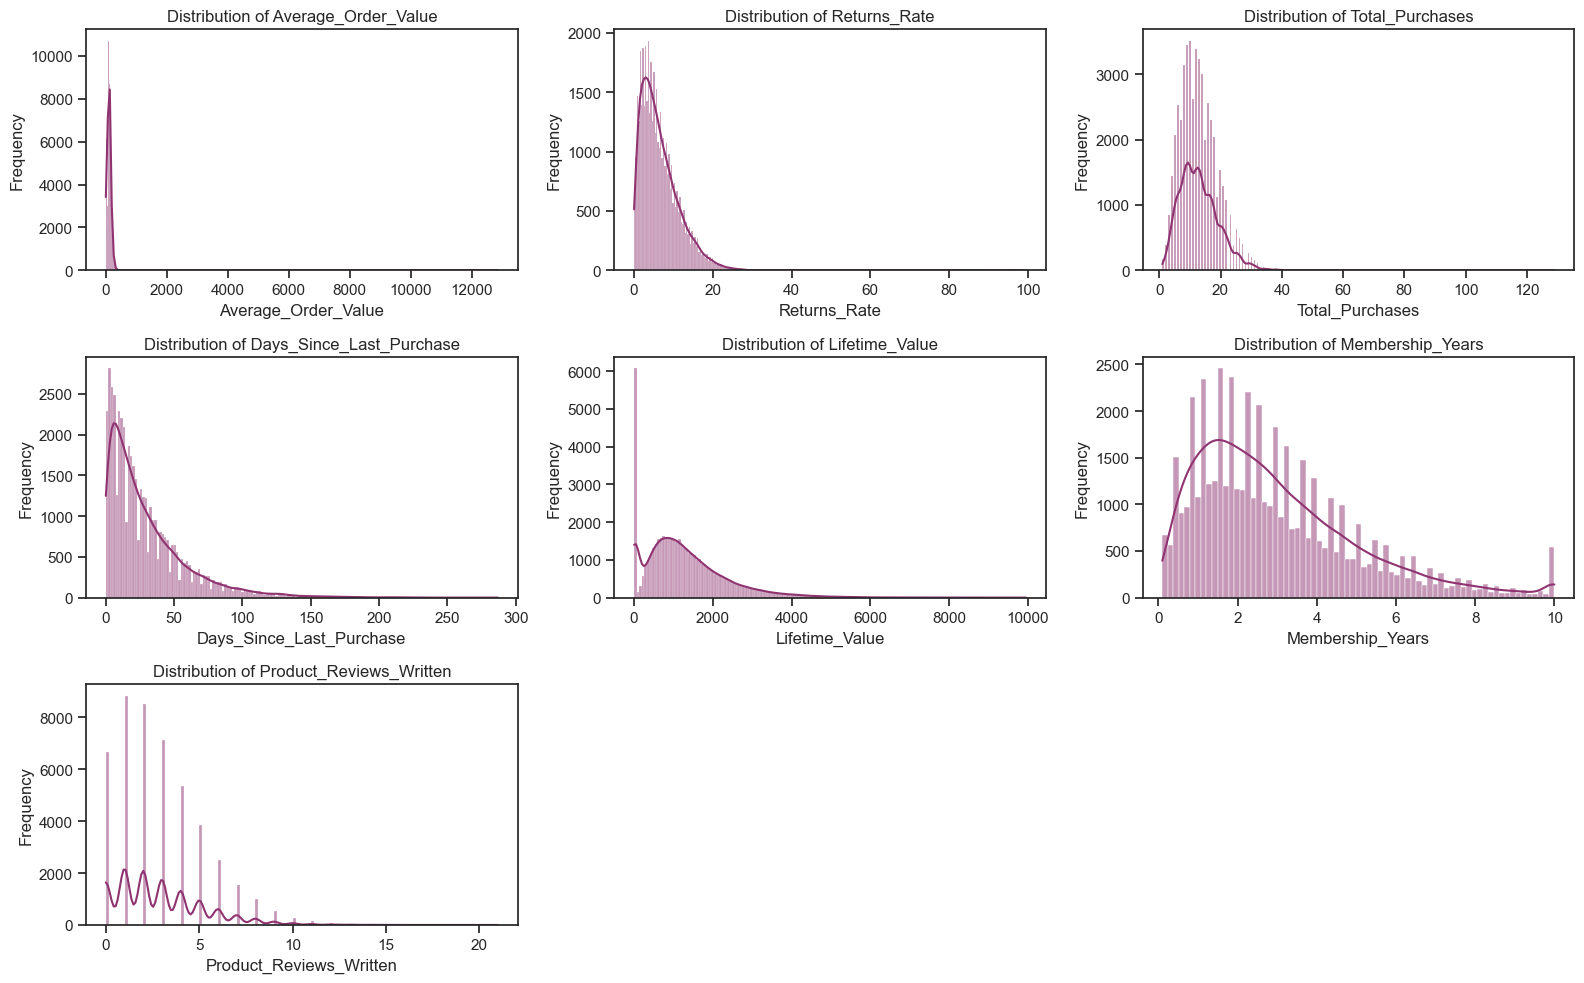

In [99]:
fig, axes = plt.subplots(3,3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(highly_skewed):
    sns.histplot(data=df, x=feature, kde=True, ax=axes[i], color=palette[4])
    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

# hide empty plots
for j in range(len(highly_skewed), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## 3.2 Bivariate Analysis 
Analyse relationships between features and churn status.

### 3.2.1 Correlation with Churn (Numerical Features)
The direction of the relationship is expected. All very weakly correlated with churn. Customer Sevice Calls, Cart Abandonment Rate have the highest (indication of dissatisfaction pushing users to churn)

In [104]:
df_corr = df.drop(columns=cat_features)
correlations = df_corr.corr()["Churned"]

bivariate_corr = pd.DataFrame({"Correlation": correlations.sort_values(ascending=False)})
bivariate_corr

,Correlation
Churned,1.000000
Customer_Service_Calls,0.291103
Cart_Abandonment_Rate,0.277963
Days_Since_Last_Purchase,0.153360
Returns_Rate,0.054189
Average_Order_Value,0.035666
Payment_Method_Diversity,0.004524
Membership_Years,-0.000623
Lifetime_Value,-0.011018
Discount_Usage_Rate,-0.077364


#### Correlation |r| 

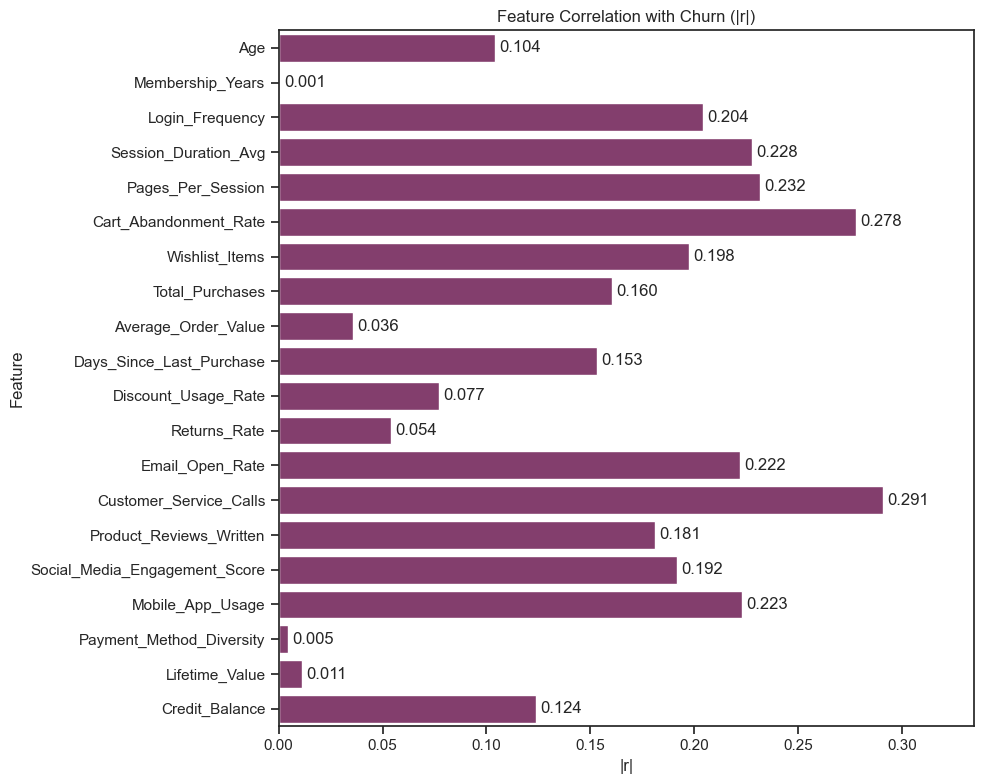

In [108]:
bivariate_corr = correlations.drop(["Churned"])
fig, ax = plt.subplots(figsize=(10, 8))

bars = sns.barplot(x=bivariate_corr.abs(), y=bivariate_corr.index, orient="h", color=palette[4], ax=ax)
ax.set_title("Feature Correlation with Churn (|r|)")
ax.set_xlabel("|r|")
ax.set_ylabel("Feature")
ax.bar_label(bars.containers[0], fmt="%.3f", clip_on=False, padding=3)
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

#### Numerical Features vs Churn Bar Plots

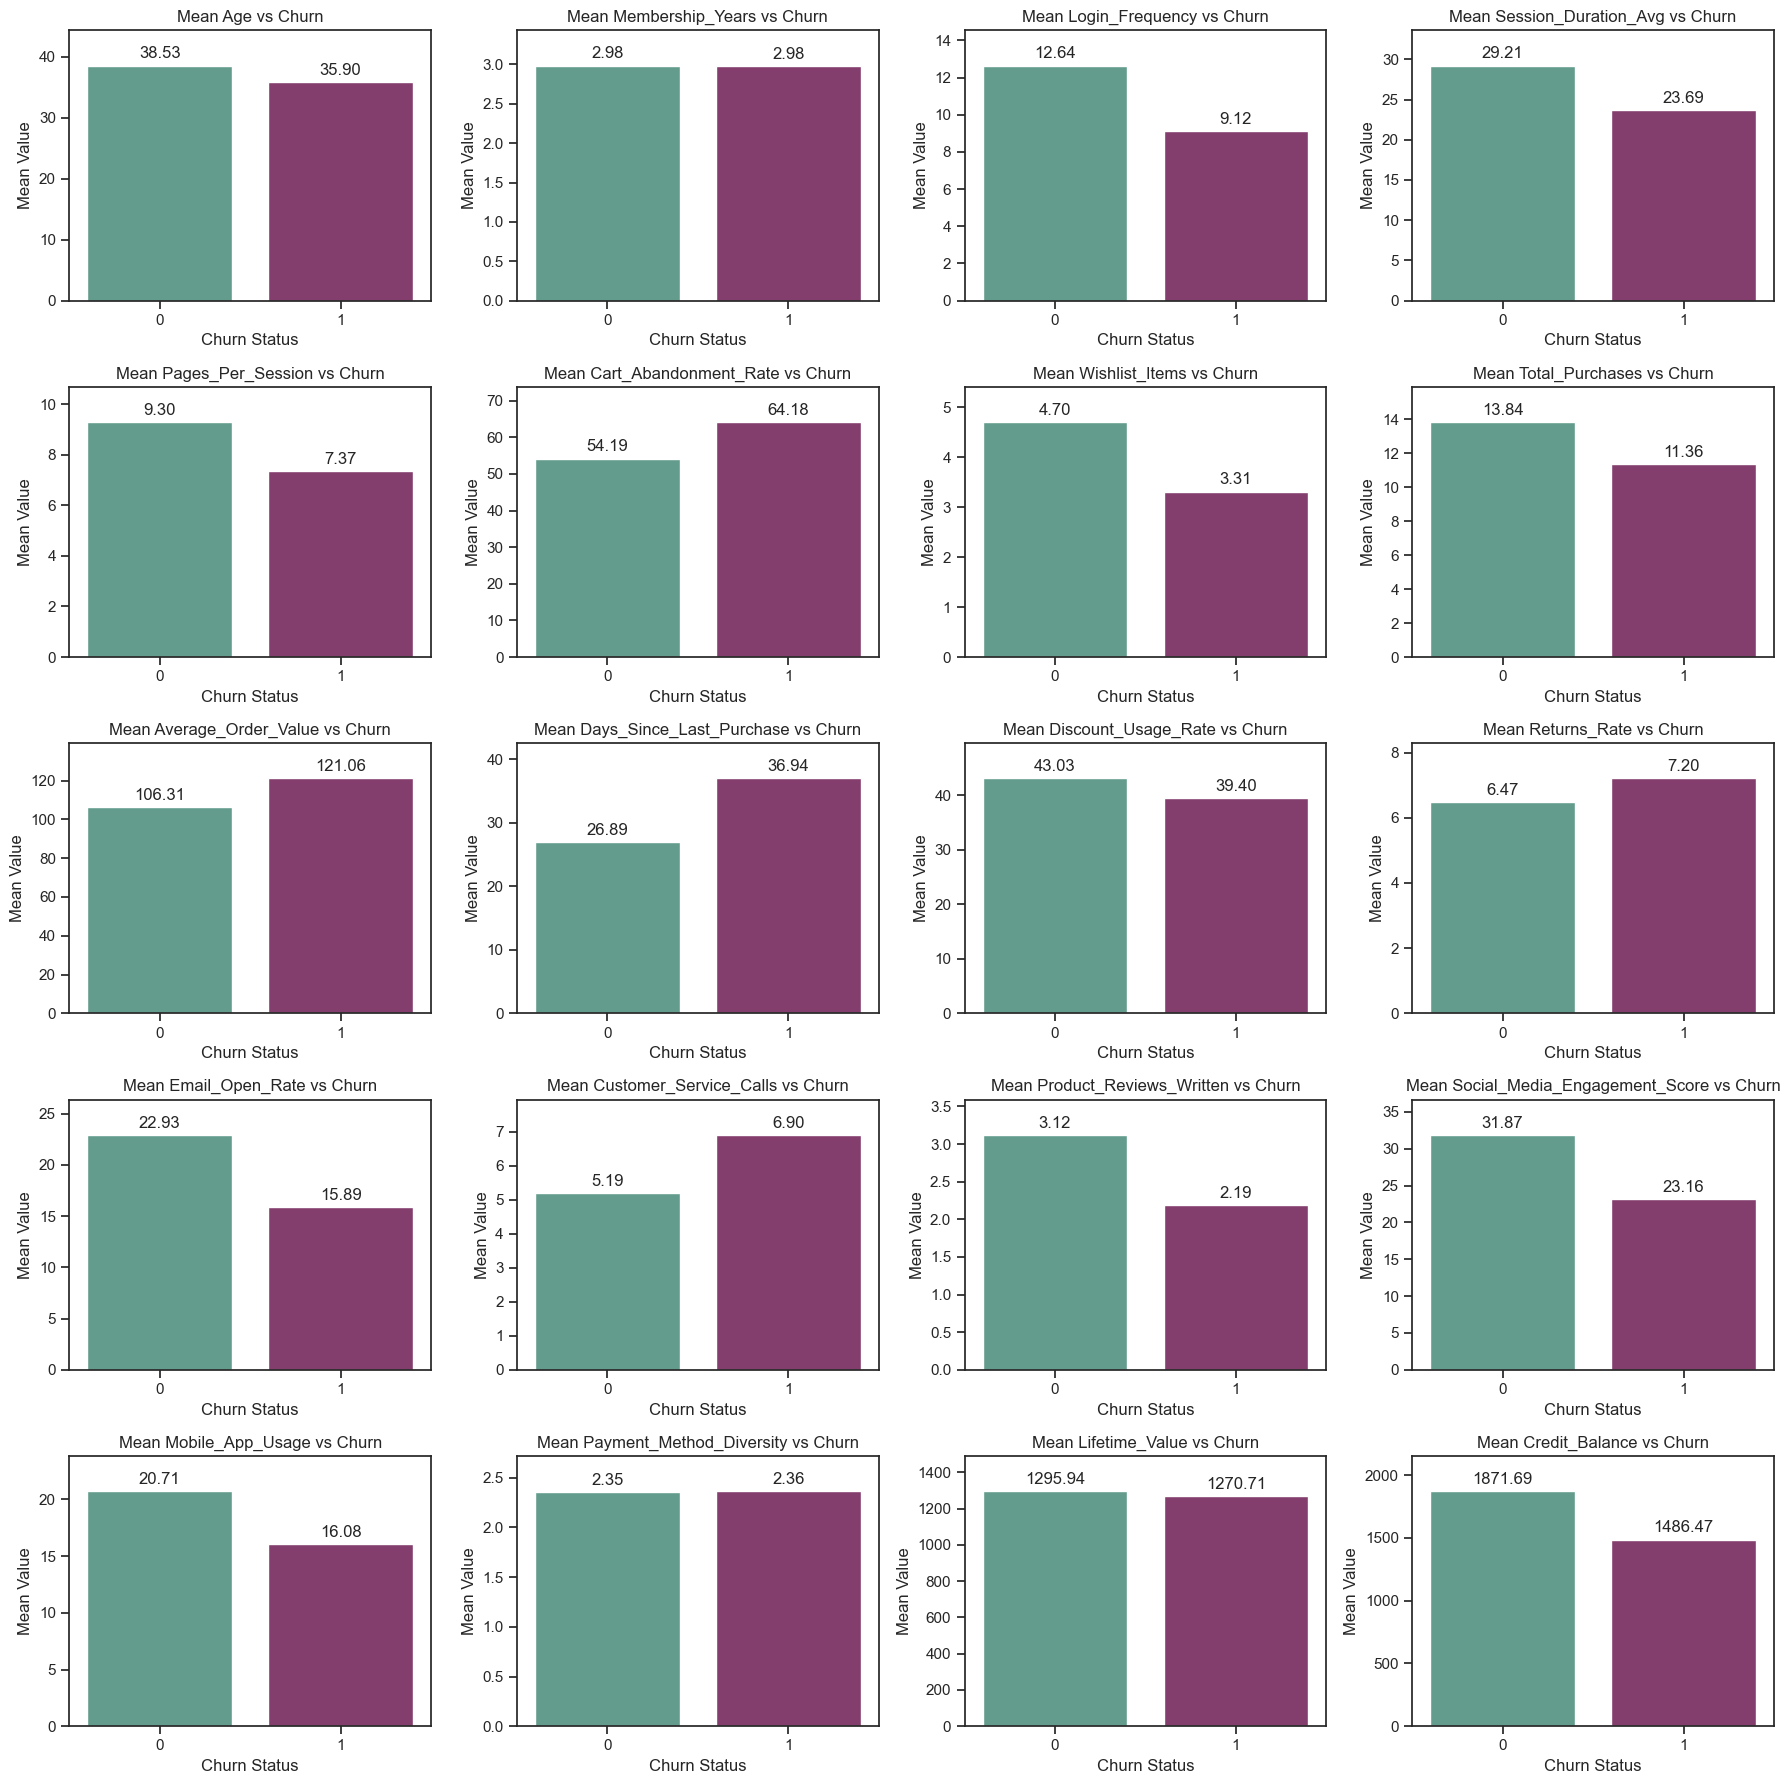

In [109]:
means = df.groupby("Churned").mean(numeric_only=True)
fig, axes = plt.subplots(5,4, figsize=(18,18))
axes = axes.flatten()

for i, feature in enumerate(means.columns):
    sns.barplot(x=means.index, y=means[feature].values, hue=means.index, palette=churn_colours, legend=False, ax=axes[i])
    axes[i].set_title(f"Mean {feature} vs Churn")
    axes[i].set_ylabel("Mean Value")
    axes[i].set_xlabel("Churn Status")
    axes[i].bar_label(axes[i].containers[0], fmt="%.2f", clip_on=False, padding=3)
    axes[i].bar_label(axes[i].containers[1], fmt="%.2f", clip_on=False, padding=3)
    axes[i].margins(y=0.15)

plt.tight_layout()
plt.show()

### 3.2.2 Discrete Numerical vs Churn
Some of these features have been grouped to show churn rate within different intervals because there are too many unique values.

In [110]:
discrete_features = ["Login_Frequency", "Wishlist_Items", "Total_Purchases", "Days_Since_Last_Purchase", "Customer_Service_Calls", 
                     "Product_Reviews_Written", "Payment_Method_Diversity"]
df_discrete_ba = df[discrete_features + ["Churned"]].copy()

# Login Frequency: min = 0, max = 46
df_discrete_ba["Grp_Login_Frequency"] = pd.cut(df_discrete_ba["Login_Frequency"], bins=[-1, 5, 10, 20, 40, 50],labels=["0-5", "6-10", "11-20", "21-40", "41-50"])
# Days Since Last Purchase: min = 0, max = 287
df_discrete_ba["Grp_Days_Since_Last_Purchase"] = pd.cut(df_discrete_ba["Days_Since_Last_Purchase"], bins=[-1, 30, 60, 90, 180, 300], labels=["0-30", "31-60", "61-90", "91-180", "181-300"])

# Total Purchases: min = 0, max = 128
df_discrete_ba["Grp_Total_Purchases"] = pd.cut(df_discrete_ba["Total_Purchases"], bins=[-1, 0, 5, 10, 20, 40, 80, 130], labels=["0", "1-5", "6-10", "11-20", "21-40", "41-80", "81-130"])

features_to_plot = ["Grp_Login_Frequency", "Grp_Days_Since_Last_Purchase", "Grp_Total_Purchases","Wishlist_Items", "Customer_Service_Calls", "Product_Reviews_Written","Payment_Method_Diversity"]

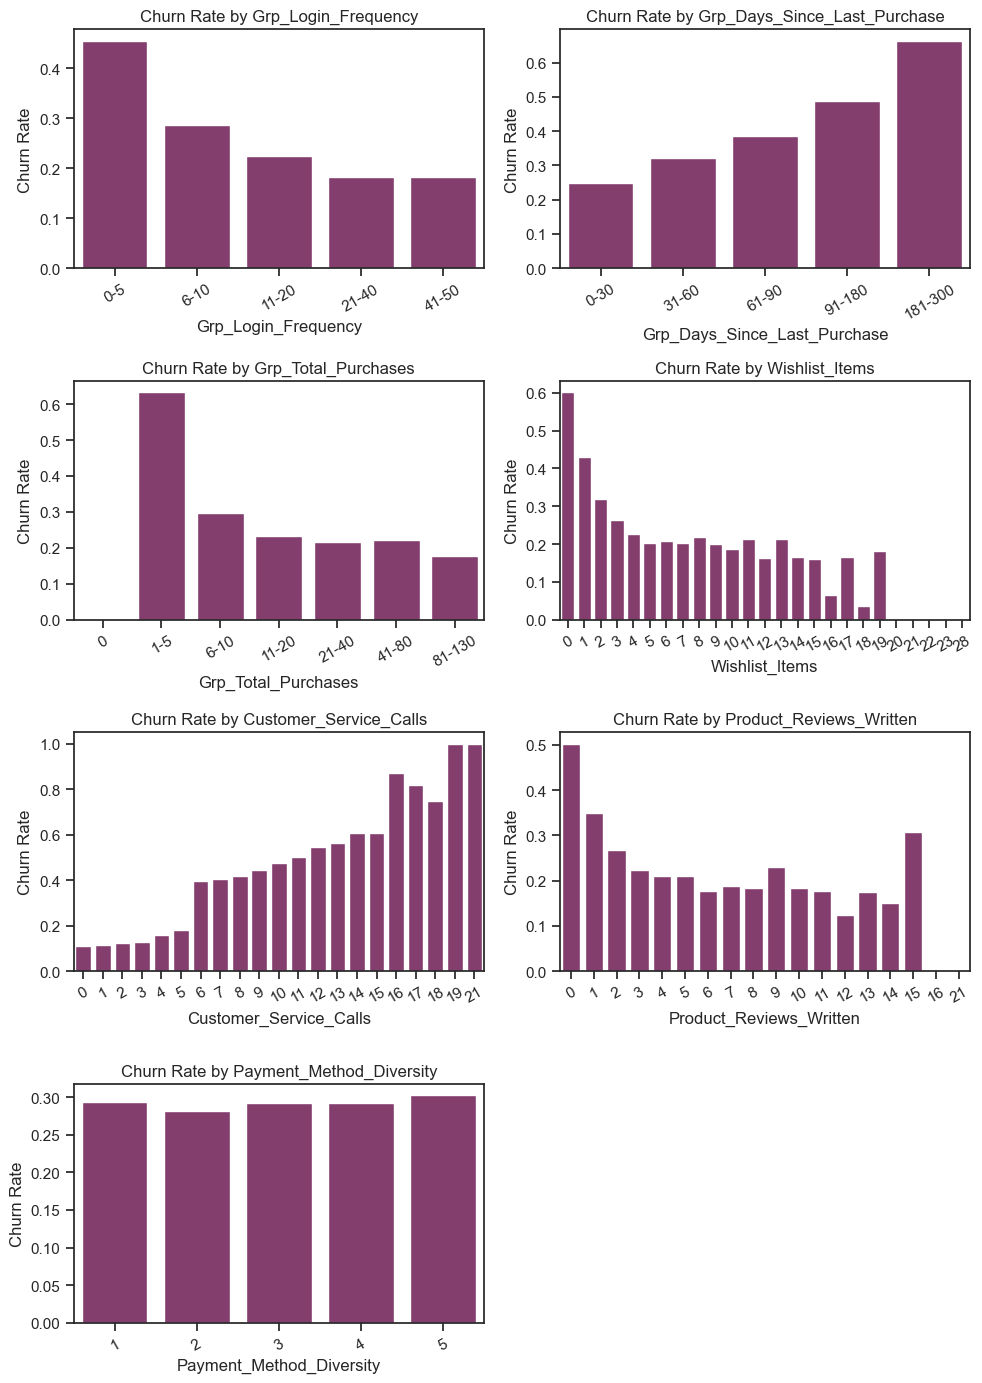

In [119]:
fig, axes = plt.subplots(4,2, figsize=(10,14))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    churn_rate = (df_discrete_ba.groupby(feature, observed=True)["Churned"].mean().reset_index())

    sns.barplot(data=churn_rate, x=feature, y="Churned", ax=axes[i], color=palette[4])

    axes[i].set_title(f"Churn Rate by {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Churn Rate")
    axes[i].tick_params(axis="x", rotation=30)
    
# hide empty plots
for j in range(len(highly_skewed), len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

### 3.2.3 Categorical Features vs Churn

#### Churn Rate by Categorical Feature 
These features don't seem to be very good at separation. There is not much variation in churn across categories -> might indicate limited association with churn.

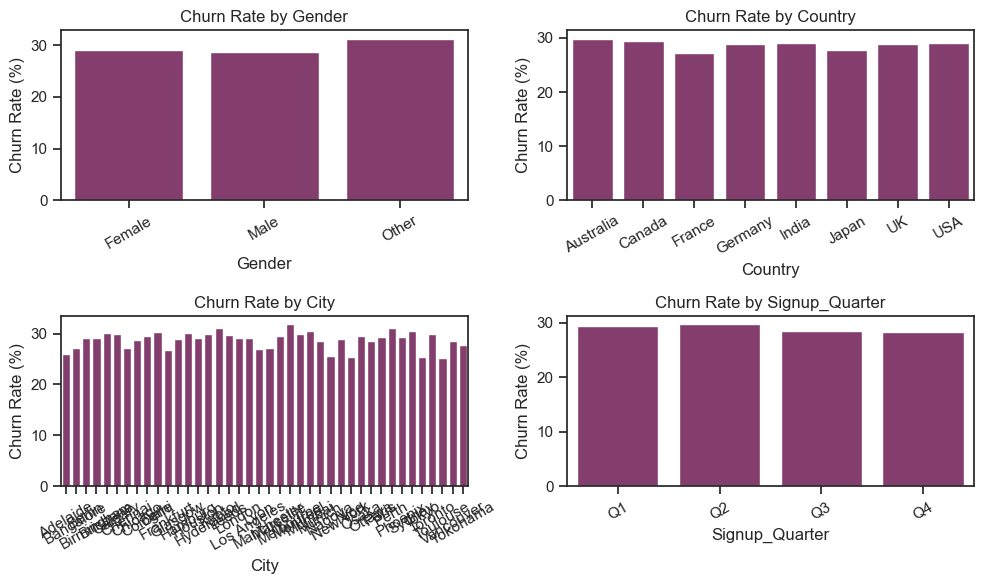

In [120]:
# bar plot
fig, axes = plt.subplots(2,2, figsize=(10,6))
axes = axes.flatten()

for i, feature in enumerate(cat_features):
    churn_rate = (df.groupby(feature, observed=True)["Churned"].mean().reset_index())
    churn_rate["Churned"] *= 100 # percentage
    
    sns.barplot(data=churn_rate, x=feature, y="Churned", ax=axes[i], color=palette[4])
    axes[i].set_title(f"Churn Rate by {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].tick_params(axis="x", rotation=30)
    
plt.tight_layout()
plt.show()

#### Association with Churn (Cramer's V & Chi Squared)
To quantify what was observed above:\
Chi-squared tests indicate that Gender, Country and City are not significantly associated with churn. Signup Quarter is the only statistically significant variable, its low Cramer's V shows that the strength of that association is weak though.

Overall, the categorical features show very little association with churn. Therefore, performance will be tested with the removal of each variable.

In [121]:
from itertools import combinations
from scipy import stats

results = []
for feature in cat_features:
    c_tbl = pd.crosstab(df[feature], df["Churned"])

    chi2, p_value, _, _ = stats.chi2_contingency(c_tbl, correction=False)

    n = c_tbl.sum().sum()
    minDim = min(c_tbl.shape) - 1

    V = np.sqrt((chi2/n) / minDim)

    results.append({"Feature": feature, "Chi-Square": chi2, "P-Value": p_value, "Cramer's V": V})

df_results = pd.DataFrame(results)
df_results

,Feature,Chi-Square,P-Value,Cramer's V
0,Gender,2.963880,0.227196,0.007699
1,Country,9.439601,0.222616,0.013740
2,City,42.025301,0.341206,0.028991
3,Signup_Quarter,9.144817,0.027426,0.013524


## 3.3 Multivariate Analysis
Analysis of feature-feature relationships.From a modelling perspective, this is mostly relevant for LR -> assumption that there is no mulitcollinearity.\
Cramer's V matrix will be equivalent to the correlation matrix for categoricals

### 3.3.1 Multivariate Correlation

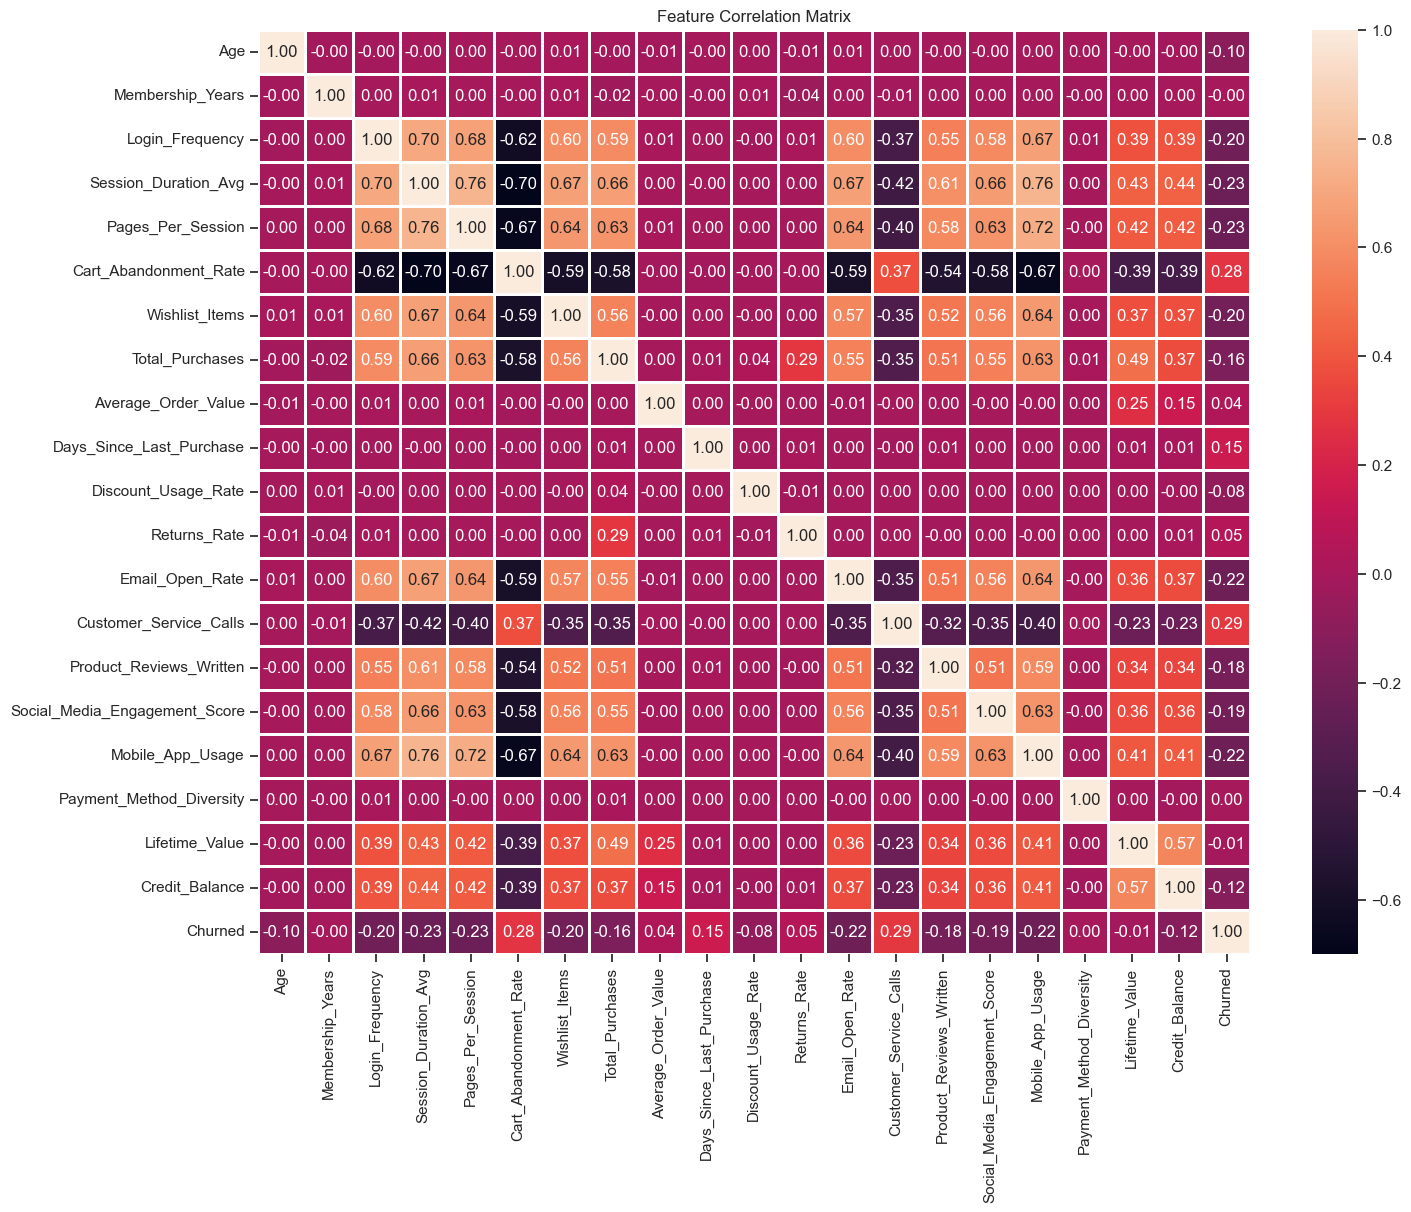

In [122]:
multivariate_corr = df_corr.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(multivariate_corr, annot=True, fmt=".2f", linewidth=2)
plt.title("Feature Correlation Matrix")
plt.show()

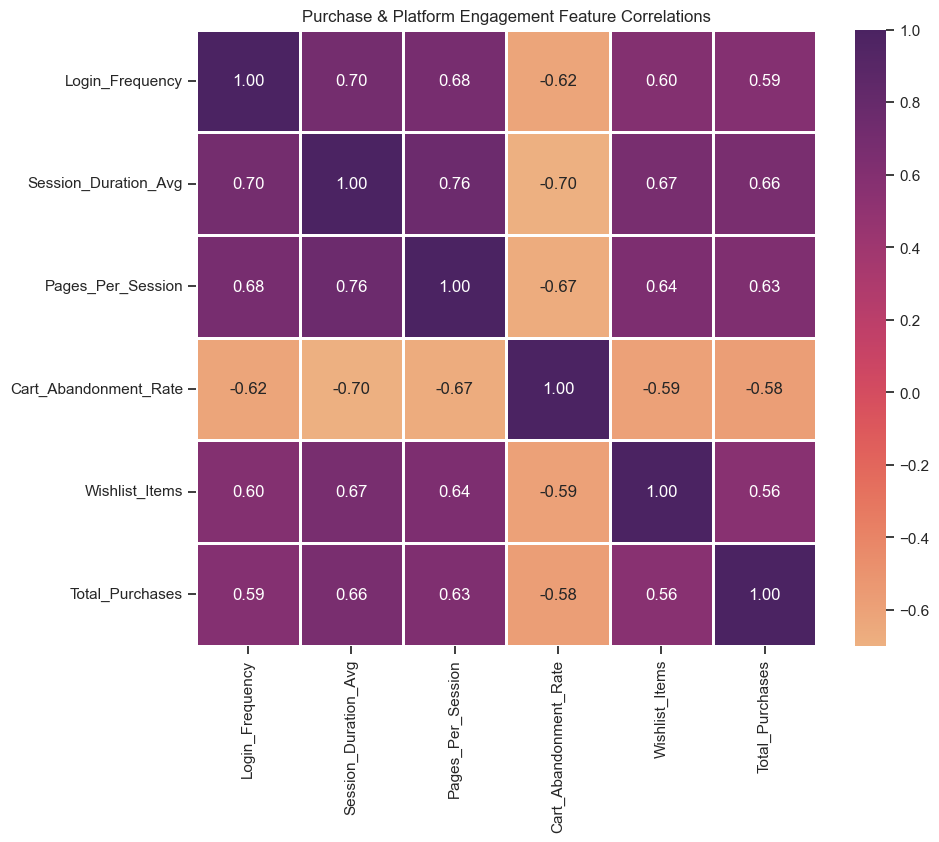

In [125]:
df_corr_zoom = df_corr[["Login_Frequency", "Session_Duration_Avg", "Pages_Per_Session", "Cart_Abandonment_Rate", "Wishlist_Items",
                         "Total_Purchases"]].corr()

plt.figure(figsize=(10,8))
sns.heatmap(df_corr_zoom, annot=True, fmt=".2f", linewidth=2, cmap="flare")
plt.title("Purchase & Platform Engagement Feature Correlations")
plt.show()

### 3.3.2 Cramér's V (Multivariate Categorical Association)
Cramer's V gets the strength of the association between categorical features. There is very little association between features but country and city have a Cramer's V of 1.00 

In [130]:
cramers_mtrx = pd.DataFrame(
    np.eye(len(cat_features)),index=cat_features, columns=cat_features)

In [131]:
# https://www.statology.org/cramers-v-in-python/
for f1, f2 in combinations(cat_features, 2):
    c_tbl = pd.crosstab(df[f1], df[f2]) # contingency tabe
    X2 = stats.chi2_contingency(c_tbl, correction=False)[0] #chi2 test
    n = c_tbl.sum().sum() # sample size
    minDim = min(c_tbl.shape)-1 # min dimension
    #cramers v
    V = np.sqrt((X2/n)/minDim)

    cramers_mtrx.loc[f1,f2] = V
    cramers_mtrx.loc[f2,f1] = V

#cramers_mtrx

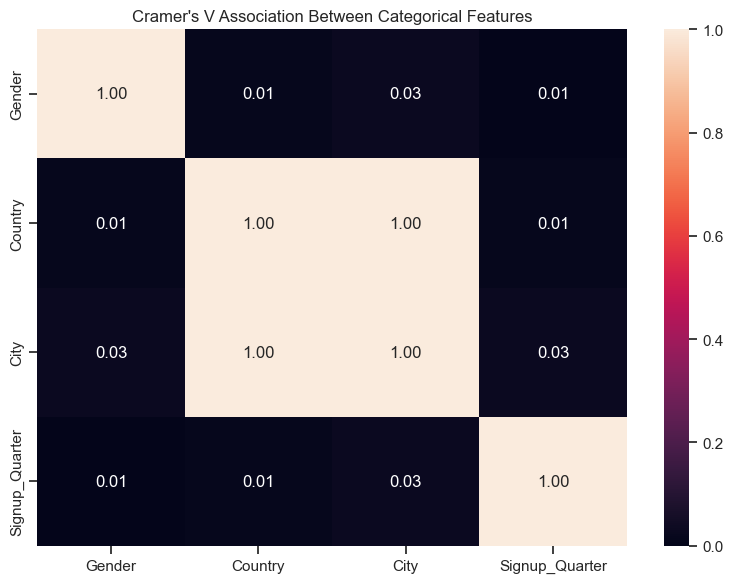

In [132]:
plt.figure(figsize=(8,6))
sns.heatmap(cramers_mtrx, annot=True, vmin=0, vmax=1, fmt=".2f")
plt.title("Cramer's V Association Between Categorical Features")
plt.tight_layout()
plt.show()

### 2.3.4 Correlation Ratio (Association Between Numerical & Categorical)
Correlation ratio to measure how strongly the numerical variables vary according to the categories (of the cat feature)\
(Note: this measure does not necessarily identify multicollinearity)

η < 0.1 -> basically none\ η 0.1-0.3 -> weak\ η 0.3-0.5 -> moderate\ η > 0.5 -> strong

In [133]:
eta_matrix = pd.DataFrame(index=cat_features, columns=num_features)

for cat in cat_features:
    for num in num_features:
        data = df[[cat, num]].dropna()
        overall_mean = data[num].mean()
        numerator = 0

        for category in data[cat].unique():
            group = data[data[cat] == category][num]
            numerator += len(group) * (group.mean() - overall_mean) ** 2

        denominator = ((data[num] - overall_mean) ** 2).sum()

        eta = np.sqrt(numerator / denominator)
        eta_matrix.loc[cat, num] = eta

eta_matrix = eta_matrix.astype(float)
eta_matrix

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance
Gender,0.001708,0.003464,0.009242,0.003992,0.001277,0.004367,0.005920,0.006417,0.007265,0.008440,0.005501,0.003981,0.002357,0.000587,0.004103,0.006584,0.006317,0.003980,0.003281,0.004759
Country,0.016187,0.011800,0.014534,0.009473,0.009420,0.012246,0.010470,0.008762,0.254452,0.012680,0.011808,0.012195,0.014222,0.012532,0.009264,0.009305,0.009551,0.016056,0.529403,0.529536
City,0.029625,0.030643,0.025377,0.028678,0.025873,0.024460,0.031530,0.025031,0.255008,0.029003,0.029411,0.029480,0.030106,0.025064,0.031967,0.028056,0.027698,0.031853,0.529833,0.529894
Signup_Quarter,0.007606,0.001302,0.002363,0.001409,0.005694,0.014844,0.002842,0.224516,0.007716,0.011604,0.165869,0.012257,0.003892,0.004453,0.008311,0.006155,0.004443,0.004861,0.003540,0.005430


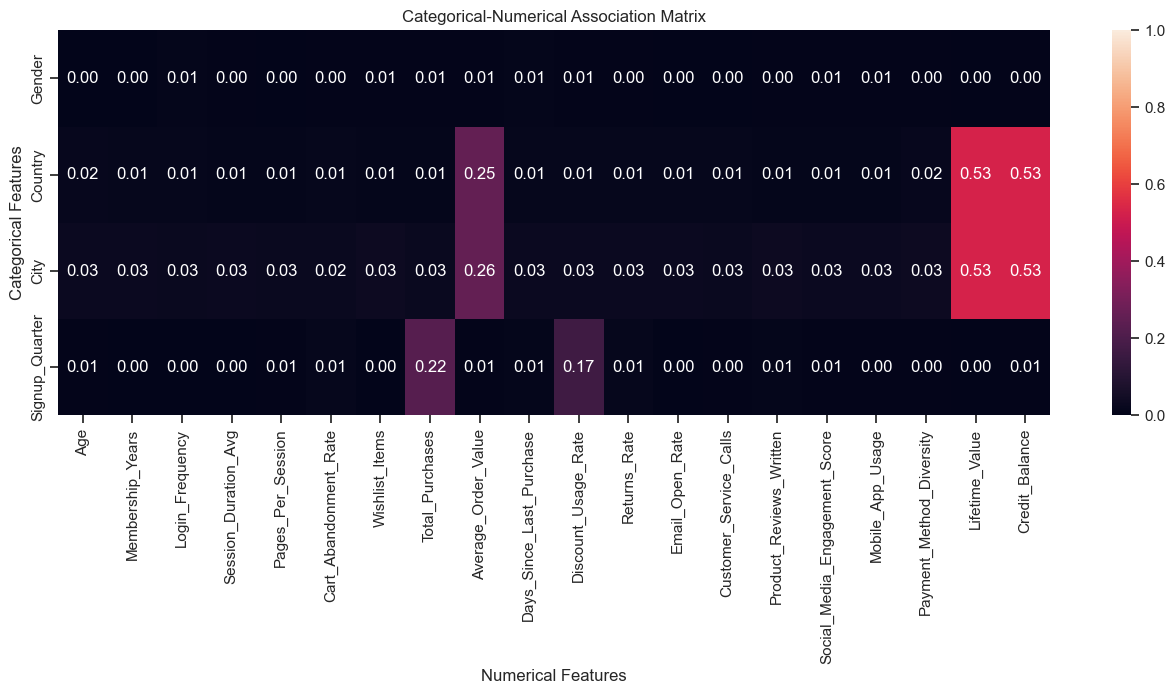

In [134]:
plt.figure(figsize=(16,5))
sns.heatmap(eta_matrix, annot=True, fmt=".2f", vmin=0, vmax=1)
plt.title("Categorical-Numerical Association Matrix")
plt.xlabel("Numerical Features")
plt.ylabel("Categorical Features")
plt.show()

Correlation ratio measures the strength of relationship between a categorical variable and a numerical variable -> will determine whether the mean of the num variable changes substantially between categories

Almost all of the categorical features have little to no association with the categorical ones. Only city and country have a strong association with lifetime value and credit balance (0.53). Reflection of the Cramer's V between country and city being 1.00?

---
# 4. PREPROCESSING


## 4.1 Train Test Split
Stratified train-test split (80% training, 20% testing) 

In [141]:
X = df.drop(["Churned", "City"], axis=1) 
y = df["Churned"]

In [145]:
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

In [146]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## 4.2 Imputation (miceforest)

In [143]:
X_train_mice = X_train.copy().reset_index(drop=True)
X_test_mice = X_test.copy().reset_index(drop=True)

In [147]:
# to point out the categorical features
for col in cat_cols:
    X_train_mice[col] = X_train_mice[col].astype("category")
    X_test_mice[col] = X_test_mice[col].astype("category")

    X_test_mice[col] = X_test_mice[col].cat.set_categories(X_train_mice[col].cat.categories)

In [148]:
mice_kernel = mf.ImputationKernel(X_train_mice, num_datasets=1, random_state=42)
# impute training data
X_train_imputed = mice_kernel.complete_data()
X_test_imputed = mice_kernel.impute_new_data(X_test_mice).complete_data()

## 4.3 LR Transformer
71 features with City...32 without it

In [149]:
skewed_cols = [col for col in num_cols if col in highly_skewed]
normal_num_cols = [col for col in num_cols if col not in skewed_cols]

In [150]:
lr_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
    ("num", StandardScaler(), normal_num_cols),
    ("log", make_pipeline(
        FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()
    ), skewed_cols)
])

X_train_lr = lr_preprocessor.fit_transform(X_train_imputed)
X_test_lr = lr_preprocessor.transform(X_test_imputed)

#### Check VIF

In [152]:
X_nums = X_train_imputed.select_dtypes(include="number")
X_nums = X_nums.apply(pd.to_numeric, errors="coerce").astype("float64") #conv to float
Xc_nums = sm.add_constant(X_nums)

df_vif = pd.DataFrame({
    "Feature": X_nums.columns,
    "VIF": [variance_inflation_factor(Xc_nums.values, i+1) for i in range(X_nums.shape[1])]
})
df_vif.sort_values("VIF", ascending=False)

,Feature,VIF
3,Session_Duration_Avg,2.790323
7,Total_Purchases,2.526807
4,Pages_Per_Session,2.454150
2,Login_Frequency,2.413743
5,Cart_Abandonment_Rate,2.337352
16,Mobile_App_Usage,2.211389
12,Email_Open_Rate,1.923888
6,Wishlist_Items,1.828681
18,Lifetime_Value,1.733457
15,Social_Media_Engagement_Score,1.662529


## 4.4 Tree Transformer

In [151]:
t_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
    ("num", "passthrough", num_cols)
])

X_train_t = t_preprocessor.fit_transform(X_train_imputed)
X_test_t = t_preprocessor.transform(X_test_imputed)

---
# 5. BASELINE MODEL TRAINING

In [180]:
base_lr = LogisticRegression(random_state=42, max_iter=8000, class_weight="balanced")
base_lr.fit(X_train_lr, y_train)
base_lr_pred = base_lr.predict(X_test_lr)
base_lr_proba = base_lr.predict_proba(X_test_lr)[:,1]

In [166]:
base_dt = DecisionTreeClassifier(random_state=42, class_weight="balanced")
base_dt.fit(X_train_t, y_train)
base_dt_pred = base_dt.predict(X_test_t)
base_dt_proba = base_dt.predict_proba(X_test_t)[:,1]

In [167]:
base_rf = RandomForestClassifier(random_state=42, class_weight="balanced")
base_rf.fit(X_train_t, y_train)
base_rf_pred = base_rf.predict(X_test_t)
base_rf_proba = base_rf.predict_proba(X_test_t)[:,1]

In [156]:
scale_pos_weight = ((y_train == 0).sum()) / ((y_train == 1).sum()) # equiv to class_weight (2.460207612456747)

In [168]:
base_xgb = XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42)
base_xgb.fit(X_train_t, y_train)
base_xgb_pred = base_xgb.predict(X_test_t)
base_xgb_proba = base_xgb.predict_proba(X_test_t)[:,1]

## 5.1 Performance Comparison

In [181]:
# without categ
df_baseline_comparison = pd.DataFrame({
    "Recall": [recall_score(y_test, base_lr_pred), recall_score(y_test, base_dt_pred), recall_score(y_test, base_rf_pred), recall_score(y_test, base_xgb_pred)],
    "Precision": [precision_score(y_test, base_lr_pred), precision_score(y_test, base_dt_pred), precision_score(y_test, base_rf_pred), precision_score(y_test, base_xgb_pred)],
    "F1-Score": [f1_score(y_test, base_lr_pred), f1_score(y_test, base_dt_pred), f1_score(y_test, base_rf_pred), f1_score(y_test, base_xgb_pred)],
    
    "PR-AUC": [average_precision_score(y_test, base_lr_proba), average_precision_score(y_test, base_dt_proba), average_precision_score(y_test, base_rf_proba), average_precision_score(y_test, base_xgb_proba)],
    "G-Mean": [geometric_mean_score(y_test, base_lr_pred, average="binary"), geometric_mean_score(y_test, base_dt_pred, average="binary"), geometric_mean_score(y_test, base_rf_pred, average="binary"), geometric_mean_score(y_test, base_xgb_pred, average="binary")],
    
    "Brier Score": [brier_score_loss(y_test, base_lr_proba), brier_score_loss(y_test, base_dt_proba), brier_score_loss(y_test, base_rf_proba), brier_score_loss(y_test, base_xgb_proba)],
    
}, index=["LR", "DT", "RF", "XGB"])
df_baseline_comparison

,Recall,Precision,F1-Score,PR-AUC,G-Mean,Brier Score
LR,0.712803,0.482097,0.575178,0.590991,0.700672,0.196165
DT,0.712457,0.709511,0.710981,0.588596,0.792454,0.167400
RF,0.705882,0.883882,0.784917,0.863169,0.824182,0.094878
XGB,0.832526,0.814765,0.823550,0.877897,0.876628,0.085350


---
# 6. HYPERPARAMETER TUNING
Maximise recall

#### *Default parameters for each model:*

In [170]:
print("Default Model Parameters:\n")
for model_name, model in models.items():
    print(f"{model_name}:")
    print(model.get_params(), "\n")

Default Model Parameters:

Logistic Regression:
{'C': 1.0, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 2000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False} 

Decision Tree:
{'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'} 

Random Forest:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 

#### *Parameter grid for each model:*

In [172]:
lr_params = {
    "C": np.logspace(-3, 2, 20),
    "penalty": ["l1", "l2"],
    "solver": ["liblinear", "saga"],
    "class_weight": [None, "balanced"],
    "max_iter": [1000, 2000]
}

dt_params = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [None, 2, 5, 7, 10, 20, 35],
    "min_samples_split": [2, 5, 10, 20, 50],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": [None, "sqrt", "log2"],
    "class_weight": ["balanced"]
}

rf_params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2", 0.5],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"]
}

xgb_params = {
    "n_estimators": [100, 200, 300, 500, 700],
    "max_depth": [2, 3, 4, 5, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.15, 0.2],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 10],
    "gamma": [0, 0.1, 0.3, 0.5, 1],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [0.1, 1, 5, 10]
}

In [187]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 6.1 Logistic Regression Tuning
Lasso introduces a regularization term that penalizes high-value coefficients and, practically, removes highly correlated features from the model (Mavrogiorgos et al., 2024)

In [182]:
lr_search = RandomizedSearchCV(estimator=base_lr, param_distributions=lr_params, n_iter=50, cv=skf, scoring="f1", n_jobs=-1, verbose=1, random_state=42)

lr_search.fit(X_train_lr, y_train)
lrc = lr_search.best_estimator_

lr_pred = lrc.predict(X_test_lr)
lr_proba = lrc.predict_proba(X_test_lr)[:,1]

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [183]:
print(f"Best F1: {lr_search.best_score_.round(2)}\n")
print(f"Best Parameters\n{lr_search.best_params_}")

print(f"\nFull Params:\n{lrc.get_params()}")

Best F1: 0.58

Best Parameters
{'solver': 'saga', 'penalty': 'l1', 'max_iter': 2000, 'class_weight': 'balanced', 'C': np.float64(0.23357214690901212)}

Full Params:
{'C': np.float64(0.23357214690901212), 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 2000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l1', 'random_state': 42, 'solver': 'saga', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


## 6.3 Decision Tree

In [178]:
dt_search = RandomizedSearchCV(estimator=base_dt, param_distributions=dt_params, n_iter=100, cv=skf, scoring="f1", n_jobs=-1, verbose=1, random_state=42)

dt_search.fit(X_train_t, y_train)
dtc = dt_search.best_estimator_

dt_pred = dtc.predict(X_test_t)
dt_proba = dtc.predict_proba(X_test_t)[:,1]

Fitting 5 folds for each of 100 candidates, totalling 500 fits


In [179]:
print(f"Best F1: {dt_search.best_score_.round(2)}\n")
print(f"Best Parameters\n{dt_search.best_params_}")

print(f"\nFull Params:\n{dtc.get_params()}")

Best F1: 0.74

Best Parameters
{'min_samples_split': 50, 'min_samples_leaf': 20, 'max_features': None, 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced'}

Full Params:
{'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 20, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


## 6.3 Random Forest

In [184]:
rf_search = RandomizedSearchCV(base_rf, rf_params, n_iter=50, scoring="f1", cv=skf, n_jobs=-1, verbose=1, random_state=42)

rf_search.fit(X_train_t, y_train)
rfc = rf_search.best_estimator_

rf_pred = rfc.predict(X_test_t)
rf_proba = rfc.predict_proba(X_test_t)[:,1]

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [185]:
print(f"Best F1: {rf_search.best_score_.round(2)}\n")
print(f"Best Parameters\n{rf_search.best_params_}")

print(f"\nFull Params:\n{rfc.get_params()}")

Best F1: 0.83

Best Parameters
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None, 'criterion': 'entropy', 'class_weight': 'balanced'}

Full Params:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': None, 'max_features': 0.5, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


## 6.4 XGBoost

In [189]:
xgb_search = RandomizedSearchCV(estimator=base_xgb, param_distributions=xgb_params, n_iter=500, cv=skf, scoring="f1", n_jobs=-1, verbose=1, random_state=42)

xgb_search.fit(X_train_t, y_train)
xgbc = xgb_search.best_estimator_

xgb_pred = xgbc.predict(X_test_t)
xgb_proba = xgbc.predict_proba(X_test_t)[:,1]

Fitting 5 folds for each of 500 candidates, totalling 2500 fits


In [190]:
print(f"Best F1: {xgb_search.best_score_.round(2)}\n")
print(f"Best Parameters\n{xgb_search.best_params_}")

print(f"\nFull Params:\n{xgbc.get_params()}")

Best F1: 0.84

Best Parameters
{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 0.9}

Full Params:
{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.9, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': 0.1, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 10, 'max_leaves': None, 'min_child_weight': 1, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 500, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': 0, 'reg_lambda': 1, 'sampling_

## 6.5 Parameter Summary & Performance Comparison 

In [191]:
df_parameters = pd.DataFrame({
    "Model": ["LR", "DT", "RF", "XGB"],
    "CV Score": [lr_search.best_score_, dt_search.best_score_, rf_search.best_score_, xgb_search.best_score_],
    "Best Parameters": [lr_search.best_params_, dt_search.best_params_, rf_search.best_params_, xgb_search.best_params_]
}).round(2)

In [192]:
df_parameters = pd.DataFrame({ "Model": ["LR", "DT", "RF", "XGB"],
    "CV Score": [lr_search.best_score_, dt_search.best_score_, rf_search.best_score_, xgb_search.best_score_],
    "Best Parameters": [lr_search.best_params_, dt_search.best_params_, rf_search.best_params_, xgb_search.best_params_]
}).round(2)

display(
    df_parameters.style.set_table_styles([{"selector": "td", "props": [("text-align", "left")]}, {"selector": "th", "props": [("text-align", "left")]}])
)

,Model,CV Score,Best Parameters
0,LR,0.580000,"{'solver': 'saga', 'penalty': 'l1', 'max_iter': 2000, 'class_weight': 'balanced', 'C': np.float64(0.23357214690901212)}"
1,DT,0.740000,"{'min_samples_split': 50, 'min_samples_leaf': 20, 'max_features': None, 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced'}"
2,RF,0.830000,"{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None, 'criterion': 'entropy', 'class_weight': 'balanced'}"
3,XGB,0.840000,"{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 0.9}"


# 7. MODEL PREDICTION & RESOURCE CONSUMPTION
Record CPU and memory usage through training and testing

In [193]:
training_results = []
testing_results = []

In [194]:
_, lr_training_resources = measure_model_operation(
    "LR", 
    lambda: lrc.fit(X_train_lr, y_train)
)

(lr_pred, lr_proba), lr_testing_resources = measure_model_operation(
    "LR",
    lambda: (
        lrc.predict(X_test_lr),
        lrc.predict_proba(X_test_lr)[:,1]
    )
)

training_results.append(lr_training_resources)
testing_results.append(lr_testing_resources)

In [195]:
_, dt_training_resources = measure_model_operation(
    "DT", 
    lambda: dtc.fit(X_train_t, y_train)
)

(dt_pred, dt_proba), dt_testing_resources = measure_model_operation(
    "DT",
    lambda: (
        dtc.predict(X_test_t),
        dtc.predict_proba(X_test_t)[:,1]
    )
)

training_results.append(dt_training_resources)
testing_results.append(dt_testing_resources)

In [196]:
_, rf_training_resources = measure_model_operation(
    "RF", 
    lambda: rfc.fit(X_train_t, y_train)
)

(rf_pred, rf_proba), rf_testing_resources = measure_model_operation(
    "RF",
    lambda: (
        rfc.predict(X_test_t),
        rfc.predict_proba(X_test_t)[:,1]
    )
)

training_results.append(rf_training_resources)
testing_results.append(rf_testing_resources)

In [197]:
_, xgb_training_resources = measure_model_operation(
    "XGB", 
    lambda: xgbc.fit(X_train_t, y_train)
)

(xgb_pred, xgb_proba), xgb_testing_resources = measure_model_operation(
    "XGB",
    lambda: (
        xgbc.predict(X_test_t),
        xgbc.predict_proba(X_test_t)[:,1]
    )
)

training_results.append(xgb_training_resources)
testing_results.append(xgb_testing_resources)

## 7.1 Resource Usage Comparison 

In [198]:
df_training_resources = pd.DataFrame(training_results).round(2).set_index("Model")
df_training_resources.index.name = None

df_testing_resources = pd.DataFrame(testing_results).round(2).set_index("Model")
df_testing_resources.index.name = None

In [199]:
df_training_resources

,Time (s),Avg CPU (%),Peak CPU (%),Avg Memory (MB),Peak Memory (MB)
LR,0.29,0.00,0.0,310.54,310.54
DT,0.52,43.70,87.4,326.36,328.89
RF,55.34,97.55,103.0,307.60,329.99
XGB,2.23,832.98,1068.3,368.89,384.75


In [200]:
df_testing_resources

,Time (s),Avg CPU (%),Peak CPU (%),Avg Memory (MB),Peak Memory (MB)
LR,0.01,55.8,55.8,320.98,320.98
DT,0.01,6.2,6.2,324.01,324.01
RF,0.44,56.0,56.0,325.13,325.13
XGB,0.04,578.8,578.8,342.45,342.45


## 7.2 Model Performance Metrics

In [201]:
lr_recall = recall_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
lr_gmean = geometric_mean_score(y_test, lr_pred, average="binary")
lr_pr_auc = average_precision_score(y_test, lr_proba)
lr_brier = brier_score_loss(y_test, lr_proba)

dt_recall = recall_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)
dt_gmean = geometric_mean_score(y_test, dt_pred, average="binary")
dt_pr_auc = average_precision_score(y_test, dt_proba)
dt_brier = brier_score_loss(y_test, dt_proba)

rf_recall = recall_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred) 
rf_f1 = f1_score(y_test, rf_pred)
rf_gmean = geometric_mean_score(y_test, rf_pred, average="binary")
rf_pr_auc = average_precision_score(y_test, rf_proba)
rf_brier = brier_score_loss(y_test, rf_proba)

xgb_recall = recall_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_gmean = geometric_mean_score(y_test, xgb_pred, average="binary")
xgb_pr_auc = average_precision_score(y_test, xgb_proba) 
xgb_brier = brier_score_loss(y_test, xgb_proba)

### 7.2.1 Evaluation Metrics

In [202]:
df_evaluation = pd.DataFrame({
    "Recall": [lr_recall, dt_recall, rf_recall, xgb_recall],
    "Precision": [lr_precision, dt_precision, rf_precision, xgb_precision],
    "F1-Score": [lr_f1, dt_f1, rf_f1, xgb_f1],
    "PR-AUC": [lr_pr_auc, dt_pr_auc, rf_pr_auc, xgb_pr_auc],
    "G-Mean": [lr_gmean, dt_gmean, rf_gmean, xgb_gmean],
    "Brier Score": [lr_brier, dt_brier, rf_brier, xgb_brier]
}, index=["LR", "DT", "RF", "XGB"])
df_evaluation

,Recall,Precision,F1-Score,PR-AUC,G-Mean,Brier Score
LR,0.714187,0.482807,0.576134,0.591401,0.701495,0.196142
DT,0.755363,0.751463,0.753408,0.817716,0.823807,0.116235
RF,0.807958,0.854685,0.830665,0.886186,0.873410,0.080750
XGB,0.818339,0.867253,0.842087,0.886843,0.881291,0.074138


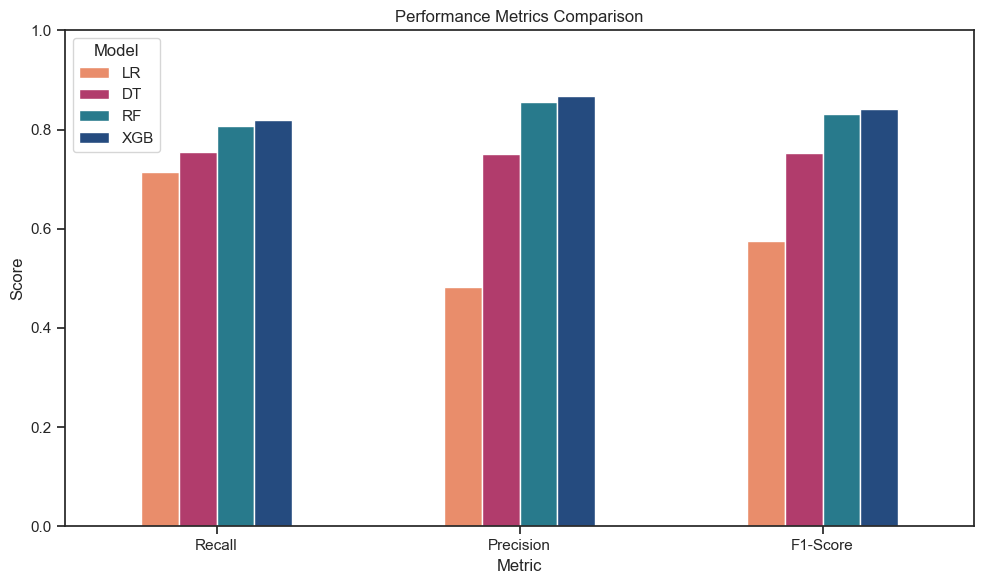

In [203]:
df_evaluation[["Recall", "Precision", "F1-Score"]].T.plot(
    kind="bar", figsize=(10, 6), color=[palette[0], palette[3], palette2[3], palette2[5]])

plt.title("Performance Metrics Comparison")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### 7.2.2 Confusion Matrix

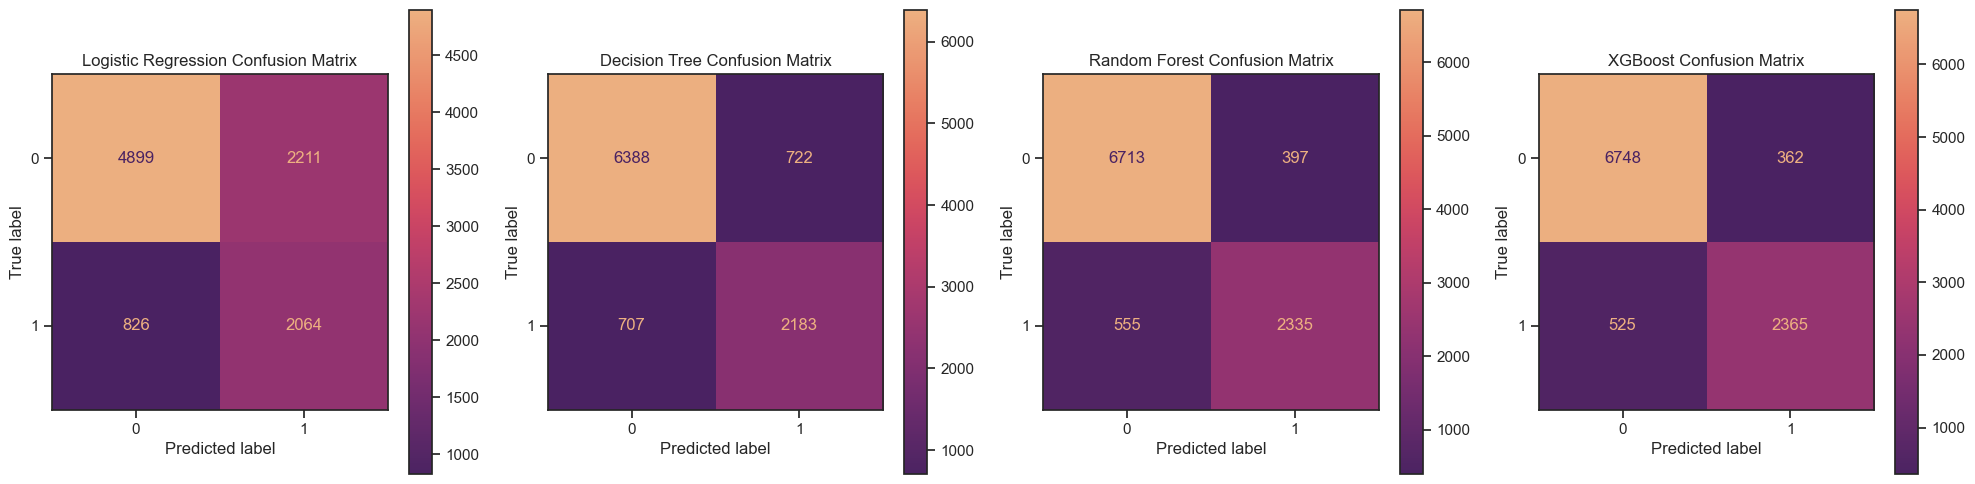

In [204]:
fig, axes = plt.subplots(1,4, figsize=(20,5))
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, ax=axes[0], cmap="flare_r")
axes[0].set_title("Logistic Regression Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, ax=axes[1], cmap="flare_r")
axes[1].set_title("Decision Tree Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, ax=axes[2], cmap="flare_r")
axes[2].set_title("Random Forest Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, xgb_pred, ax=axes[3], cmap="flare_r")
axes[3].set_title("XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

### 7.2.3 Precision-Recall Curves

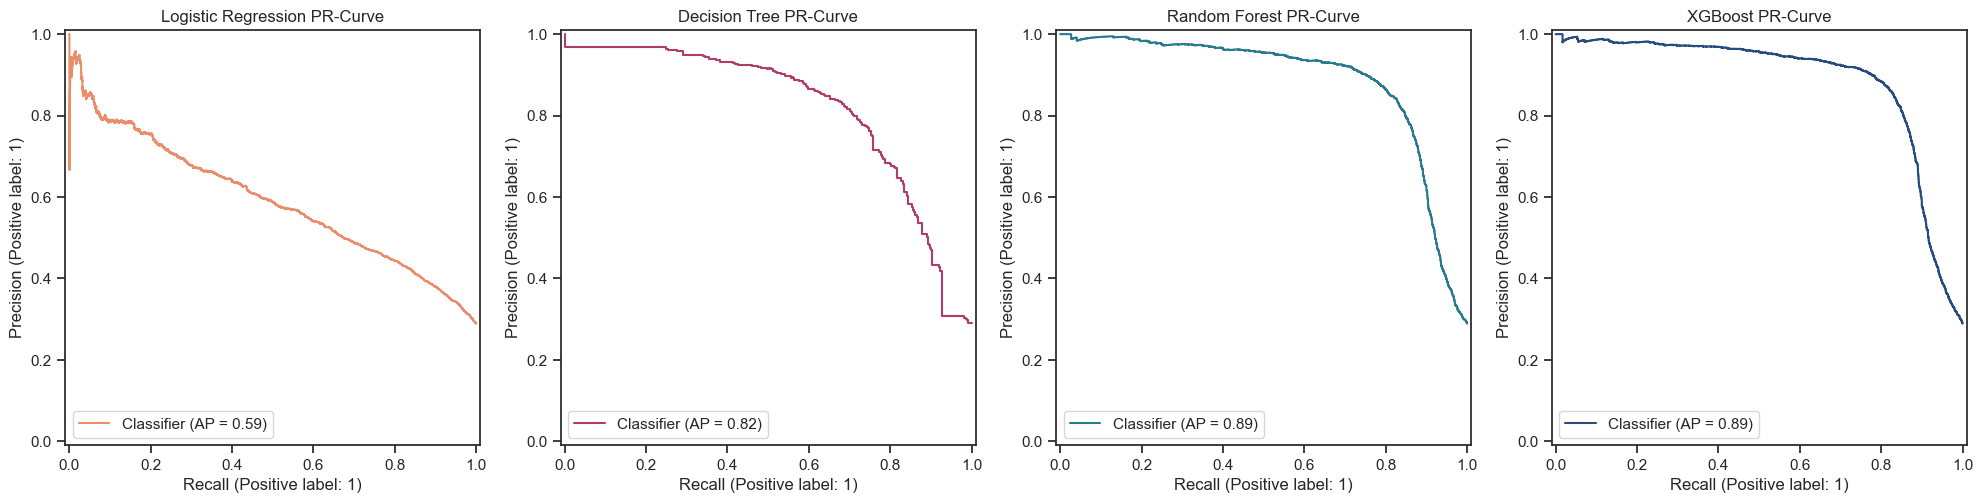

In [205]:
fig, axes = plt.subplots(1,4, figsize=(20,5))
PrecisionRecallDisplay.from_predictions(y_test, lr_proba, ax=axes[0], color=palette[0])
axes[0].set_title("Logistic Regression PR-Curve")

PrecisionRecallDisplay.from_predictions(y_test, dt_proba, ax=axes[1], color=palette[3])
axes[1].set_title("Decision Tree PR-Curve")

PrecisionRecallDisplay.from_predictions(y_test, rf_proba, ax=axes[2], color=palette2[3])
axes[2].set_title("Random Forest PR-Curve")

PrecisionRecallDisplay.from_predictions(y_test, xgb_proba, ax=axes[3], color=palette2[5])
axes[3].set_title("XGBoost PR-Curve")

plt.tight_layout()
plt.show()

### 7.2.4 Calibration Curves
How closely the predicted probabilities match the actual probabilities
"The purpose of probability calibration is to ensure that the predicted probabilities are well-calibrated i.e., that a predicted probability of, say, 0.8 corresponds to an actual likelihood of the positive class being true of roughly 0.8."

In [208]:
p = y_test.mean() #churn rate
baseline_proba = np.full(len(y_test), p) #same pred for every customer
#show calculation
print(f"baseline = p x (1 - p)\nbaseline = {p} x (1 - {p})\n\t = {p} x {np.round(1-p, 3)}\n")

brier_baseline = brier_score_loss(y_test, baseline_proba)

print("Baseline Brier:", np.round(brier_baseline, 3), "(reference point)") #= p * (1-p)

baseline = p x (1 - p)
baseline = 0.289 x (1 - 0.289)
	 = 0.289 x 0.711

Baseline Brier: 0.205 (reference point)


In [209]:
for name, proba in models.items():
    prob_true, prob_pred = calibration_curve(y_test, proba, n_bins=5)
    print(f"{name}:")
    print("- prob_true:  ", np.round(prob_true, 3))
    print("- prob_pred:  ", np.round(prob_pred, 3))

    bins = np.linspace(0, 1, 6)
    counts, _ = np.histogram(proba, bins=bins)
    print("- n_customers:", counts) #per bin

LR:
- prob_true:   [0.07  0.133 0.279 0.493 0.756]
- prob_pred:   [0.131 0.302 0.498 0.695 0.858]
- n_customers: [1538 2756 2780 2173  753]
DT:
- prob_true:   [0.064 0.139 0.303 0.51  0.855]
- prob_pred:   [0.11  0.276 0.484 0.717 0.955]
- n_customers: [4856 1656  809  551 2128]
RF:
- prob_true:   [0.05  0.134 0.445 0.793 0.947]
- prob_pred:   [0.093 0.285 0.501 0.706 0.927]
- n_customers: [5818 1137  652  702 1691]
XGB:
- prob_true:   [0.057 0.221 0.428 0.676 0.92 ]
- prob_pred:   [0.04  0.288 0.499 0.709 0.963]
- n_customers: [6713  412  292  343 2240]


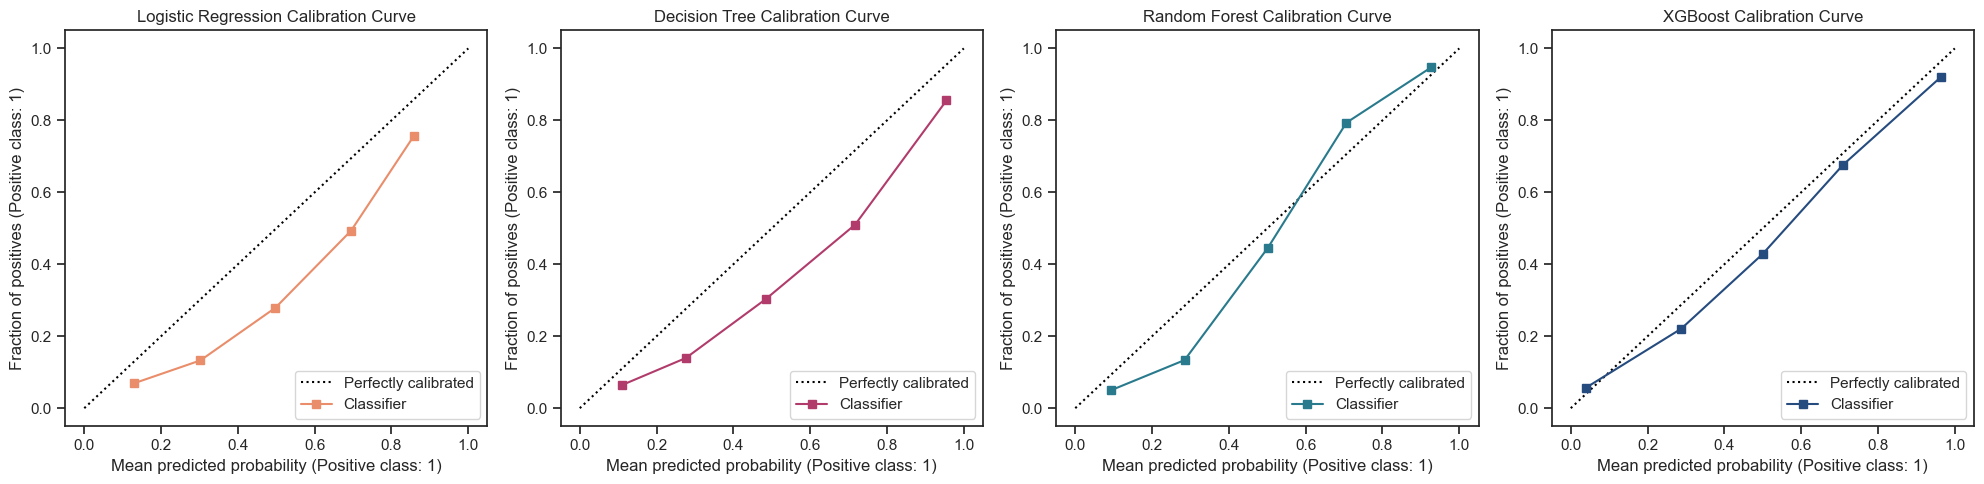

In [210]:
fig, axes = plt.subplots(1,4, figsize=(20,5))
CalibrationDisplay.from_predictions(y_test, lr_proba, ax=axes[0], color=palette[0])
axes[0].set_title("Logistic Regression Calibration Curve")

CalibrationDisplay.from_predictions(y_test, dt_proba, ax=axes[1], color=palette[3])
axes[1].set_title("Decision Tree Calibration Curve")

CalibrationDisplay.from_predictions(y_test, rf_proba, ax=axes[2], color=palette2[3])
axes[2].set_title("Random Forest Calibration Curve")

CalibrationDisplay.from_predictions(y_test, xgb_proba, ax=axes[3], color=palette2[5])
axes[3].set_title("XGBoost Calibration Curve")

plt.tight_layout()
plt.show()

### 7.2.5 Cross Validation

In [211]:
from sklearn.metrics import make_scorer
models = {"LR": lrc, "DT": dtc, "RF": rfc, "XGB": xgbc}
def cross_validate_models(models, X_train_lr, X_train_t, y):
    scoring = {
        "Recall": make_scorer(recall_score),
        "Precision": make_scorer(precision_score),
        "F1": make_scorer(f1_score),
        "G-Mean": make_scorer(geometric_mean_score),
        "PR-AUC": "average_precision",
        "Brier": "neg_brier_score"
    }

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    results = []

    for name, model in models.items():
        # relevant dataset
        X = X_train_lr if name == "LR" else X_train_t

        scores = cross_validate(model, X, y_train, cv=skf, scoring=scoring, return_train_score=False, n_jobs=-1)

        results.append({
            "Model": name,
            "Recall": scores["test_Recall"].mean(),
            "Recall SD": scores["test_Recall"].std(),
            "Precision": scores["test_Precision"].mean(),
            "Precision SD": scores["test_Precision"].std(),
            "F1": scores["test_F1"].mean(),
            "F1 SD": scores["test_F1"].std(),
            "G-Mean": scores["test_G-Mean"].mean(),
            "G-Mean SD": scores["test_G-Mean"].std(),
            "PR-AUC": scores["test_PR-AUC"].mean(),
            "PR-AUC SD": scores["test_PR-AUC"].std(),
            "Brier": -scores["test_Brier"].mean(),
            "Brier SD": scores["test_Brier"].std()
        })

    return pd.DataFrame(results)

In [212]:
df_cv = cross_validate_models(models, X_train_lr, X_train_t, y_train)
df_cv = df_cv.set_index("Model")
df_cv.index.name = None
df_cv.round(3)

,Recall,Recall SD,Precision,Precision SD,F1,F1 SD,G-Mean,G-Mean SD,PR-AUC,PR-AUC SD,Brier,Brier SD
LR,0.709,0.012,0.486,0.008,0.576,0.009,0.702,0.008,0.595,0.014,0.196,0.003
DT,0.764,0.018,0.725,0.016,0.744,0.011,0.821,0.009,0.812,0.013,0.118,0.004
RF,0.796,0.005,0.862,0.008,0.828,0.006,0.869,0.004,0.883,0.009,0.082,0.003
XGB,0.806,0.007,0.876,0.007,0.840,0.006,0.877,0.005,0.885,0.010,0.075,0.003


## 8. Model Bias & Fairness Evaluation
**DI** -> the ratio of churn outcomes predicted, given the protected subset over the rest (unprotected) should be more than 80% -> DI is more regulatory/ AI governance.\
**SP** -> Compares rate at which each group recieves the positive predicition -> SP is used to assess ML and mitigate bias.

In [215]:
pred_dict = {"LR": lr_pred, "DT": dt_pred, "RF": rf_pred, "XGB": xgb_pred}

In [216]:
def summarise_fairness(predictions, y_true, sensitive_feature):
    rows = []
    for model_name, y_pred in predictions.items():
        mf = MetricFrame(metrics=selection_rate, y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_feature)

        row = mf.by_group.to_dict()
        row["SPD"]  = demographic_parity_difference(
            y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_feature
        )

        row["DIR"]  = demographic_parity_ratio(
            y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_feature
        )
        row["Model"] = model_name
        rows.append(row)
    df_summary = pd.DataFrame(rows).set_index("Model")
    df_summary.index.name = None
    return df_summary.round(3) 

In [217]:
def summarise_eq_odds(predictions, y_true, sensitive_feature):
    rows = []
    for model_name, y_pred in predictions.items():
        mf = MetricFrame(
            metrics={"TPR": true_positive_rate, "FPR": false_positive_rate},
            y_true = y_true, y_pred=y_pred, sensitive_features=sensitive_feature
        )
        row = {}
        for group, vals in mf.by_group.iterrows():
            row[f"{group} TPR"] = vals["TPR"]
            row[f"{group} FPR"] = vals["FPR"]

        row["EOD"] = equalized_odds_difference(y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_feature)
        row["EOR"] = equalized_odds_ratio(y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_feature)
        row["Model"] = model_name
        rows.append(row)
        
    df_summary = pd.DataFrame(rows).set_index("Model")
    df_summary.index.name = None
    return df_summary.round(3) 

## Fairness in Gender
the smaller the SP difference between the two groups, we can say that the model treats the unprotected
group statistically similar to the protected group.

### SPD & DIR

In [218]:
df_gender_fairness = summarise_fairness(pred_dict, y_test, X_test["Gender"])
df_gender_fairness

,Female,Male,Other,SPD,DIR
LR,0.424,0.427,0.531,0.107,0.798
DT,0.286,0.294,0.314,0.028,0.910
RF,0.269,0.276,0.320,0.051,0.841
XGB,0.268,0.275,0.343,0.075,0.782


### Equalised Odds

In [219]:
df_gender_eo = summarise_eq_odds(pred_dict, y_test, X_test["Gender"])
df_gender_eo

,Female TPR,Female FPR,Male TPR,Male FPR,Other TPR,Other FPR,EOD,EOR
LR,0.703,0.312,0.725,0.306,0.721,0.430,0.123,0.713
DT,0.749,0.100,0.762,0.104,0.754,0.079,0.025,0.758
RF,0.809,0.052,0.809,0.059,0.770,0.079,0.039,0.657
XGB,0.815,0.048,0.821,0.053,0.852,0.070,0.038,0.683


## Fairness in Country

### SPD & DIR

In [220]:
df_country_fairness = summarise_fairness(pred_dict, y_test, X_test["Country"])
df_country_fairness

,Australia,Canada,France,Germany,India,Japan,UK,USA,SPD,DIR
LR,0.448,0.429,0.408,0.438,0.420,0.417,0.438,0.422,0.040,0.912
DT,0.264,0.275,0.320,0.287,0.260,0.257,0.322,0.294,0.064,0.800
RF,0.280,0.287,0.296,0.270,0.262,0.263,0.273,0.266,0.035,0.883
XGB,0.286,0.285,0.283,0.267,0.263,0.259,0.268,0.270,0.027,0.907


### Equalised Odds

In [221]:
df_country_eo = summarise_eq_odds(pred_dict, y_test, X_test["Country"])
df_country_eo

,Australia TPR,Australia FPR,Canada TPR,Canada FPR,France TPR,France FPR,Germany TPR,Germany FPR,India TPR,India FPR,Japan TPR,Japan FPR,UK TPR,UK FPR,USA TPR,USA FPR,EOD,EOR
LR,0.763,0.315,0.695,0.313,0.695,0.285,0.696,0.334,0.695,0.312,0.682,0.317,0.730,0.327,0.720,0.300,0.081,0.854
DT,0.665,0.094,0.658,0.108,0.778,0.124,0.750,0.102,0.734,0.075,0.727,0.080,0.837,0.126,0.786,0.094,0.179,0.597
RF,0.794,0.063,0.832,0.049,0.824,0.070,0.779,0.065,0.808,0.048,0.811,0.057,0.835,0.059,0.795,0.050,0.056,0.688
XGB,0.829,0.056,0.834,0.046,0.816,0.054,0.779,0.061,0.823,0.044,0.833,0.043,0.837,0.052,0.810,0.050,0.058,0.702


---
# 8. MODEL-SPECIFIC FEATURE IMPORTANCE

## 8.1 Logistic Regression Coefficients

In [222]:
lr_feature_names = lr_preprocessor.get_feature_names_out()
lr_feature_names= [
    name.replace("cat__", "").replace("num__", "").replace("log__", "")
    for name in lr_feature_names
]

##### Full coefficient list

In [223]:
coeff = lrc.coef_[0]
df_coeff = pd.DataFrame({"Feature": lr_feature_names, "Coefficient": coeff})

df_coeff["|Coefficient|"] = df_coeff["Coefficient"].abs()
df_coeff["Effect on Churn"] = df_coeff["Coefficient"].apply(
    lambda x: "Increases churn likelihood" if x > 0 else "Decreases churn likelihood"
)

df_coeff = df_coeff.sort_values("|Coefficient|", ascending=False)

df_coeff[["Feature", "Coefficient", "Effect on Churn"]].reset_index()

,index,Feature,Coefficient,Effect on Churn
0,5,Country_India,4.232472,Increases churn likelihood
1,6,Country_Japan,4.174797,Increases churn likelihood
2,31,Lifetime_Value,0.857009,Increases churn likelihood
3,7,Country_UK,-0.761291,Decreases churn likelihood
4,27,Average_Order_Value,0.756652,Increases churn likelihood
5,3,Country_France,-0.681736,Decreases churn likelihood
6,20,Customer_Service_Calls,0.564041,Increases churn likelihood
7,4,Country_Germany,-0.552950,Decreases churn likelihood
8,16,Cart_Abandonment_Rate,0.455741,Increases churn likelihood
9,8,Country_USA,-0.431002,Decreases churn likelihood


##### Coefficients (Country grouped)

In [225]:
country_altogether = df_coeff["Feature"].str.startswith("Country_")

df_country = df_coeff[country_altogether]
df_others = df_coeff[~country_altogether]

#summary for country - for display
country_summary = pd.DataFrame({
    "Feature": ["Country (all)"],
    "Coefficient": [f"-{df_country["|Coefficient|"].min():.3f} to {df_country["|Coefficient|"].max():.3f}"],
    "Effect on Churn": ["Varies by country"]
})

# w country combined
df_grouped_coeffs = pd.concat([country_summary, df_others], ignore_index=True)
df_grouped_coeffs[["Feature", "Coefficient",  "Effect on Churn"]].head(10)

,Feature,Coefficient,Effect on Churn
0,Country (all),-0.014 to 4.232,Varies by country
1,Lifetime_Value,0.857009,Increases churn likelihood
2,Average_Order_Value,0.756652,Increases churn likelihood
3,Customer_Service_Calls,0.564041,Increases churn likelihood
4,Cart_Abandonment_Rate,0.455741,Increases churn likelihood
5,Total_Purchases,-0.336991,Decreases churn likelihood
6,Days_Since_Last_Purchase,0.316422,Increases churn likelihood
7,Age,-0.274182,Decreases churn likelihood
8,Discount_Usage_Rate,-0.197367,Decreases churn likelihood
9,Returns_Rate,0.171238,Increases churn likelihood


## 8.2 Decision Tree Plot

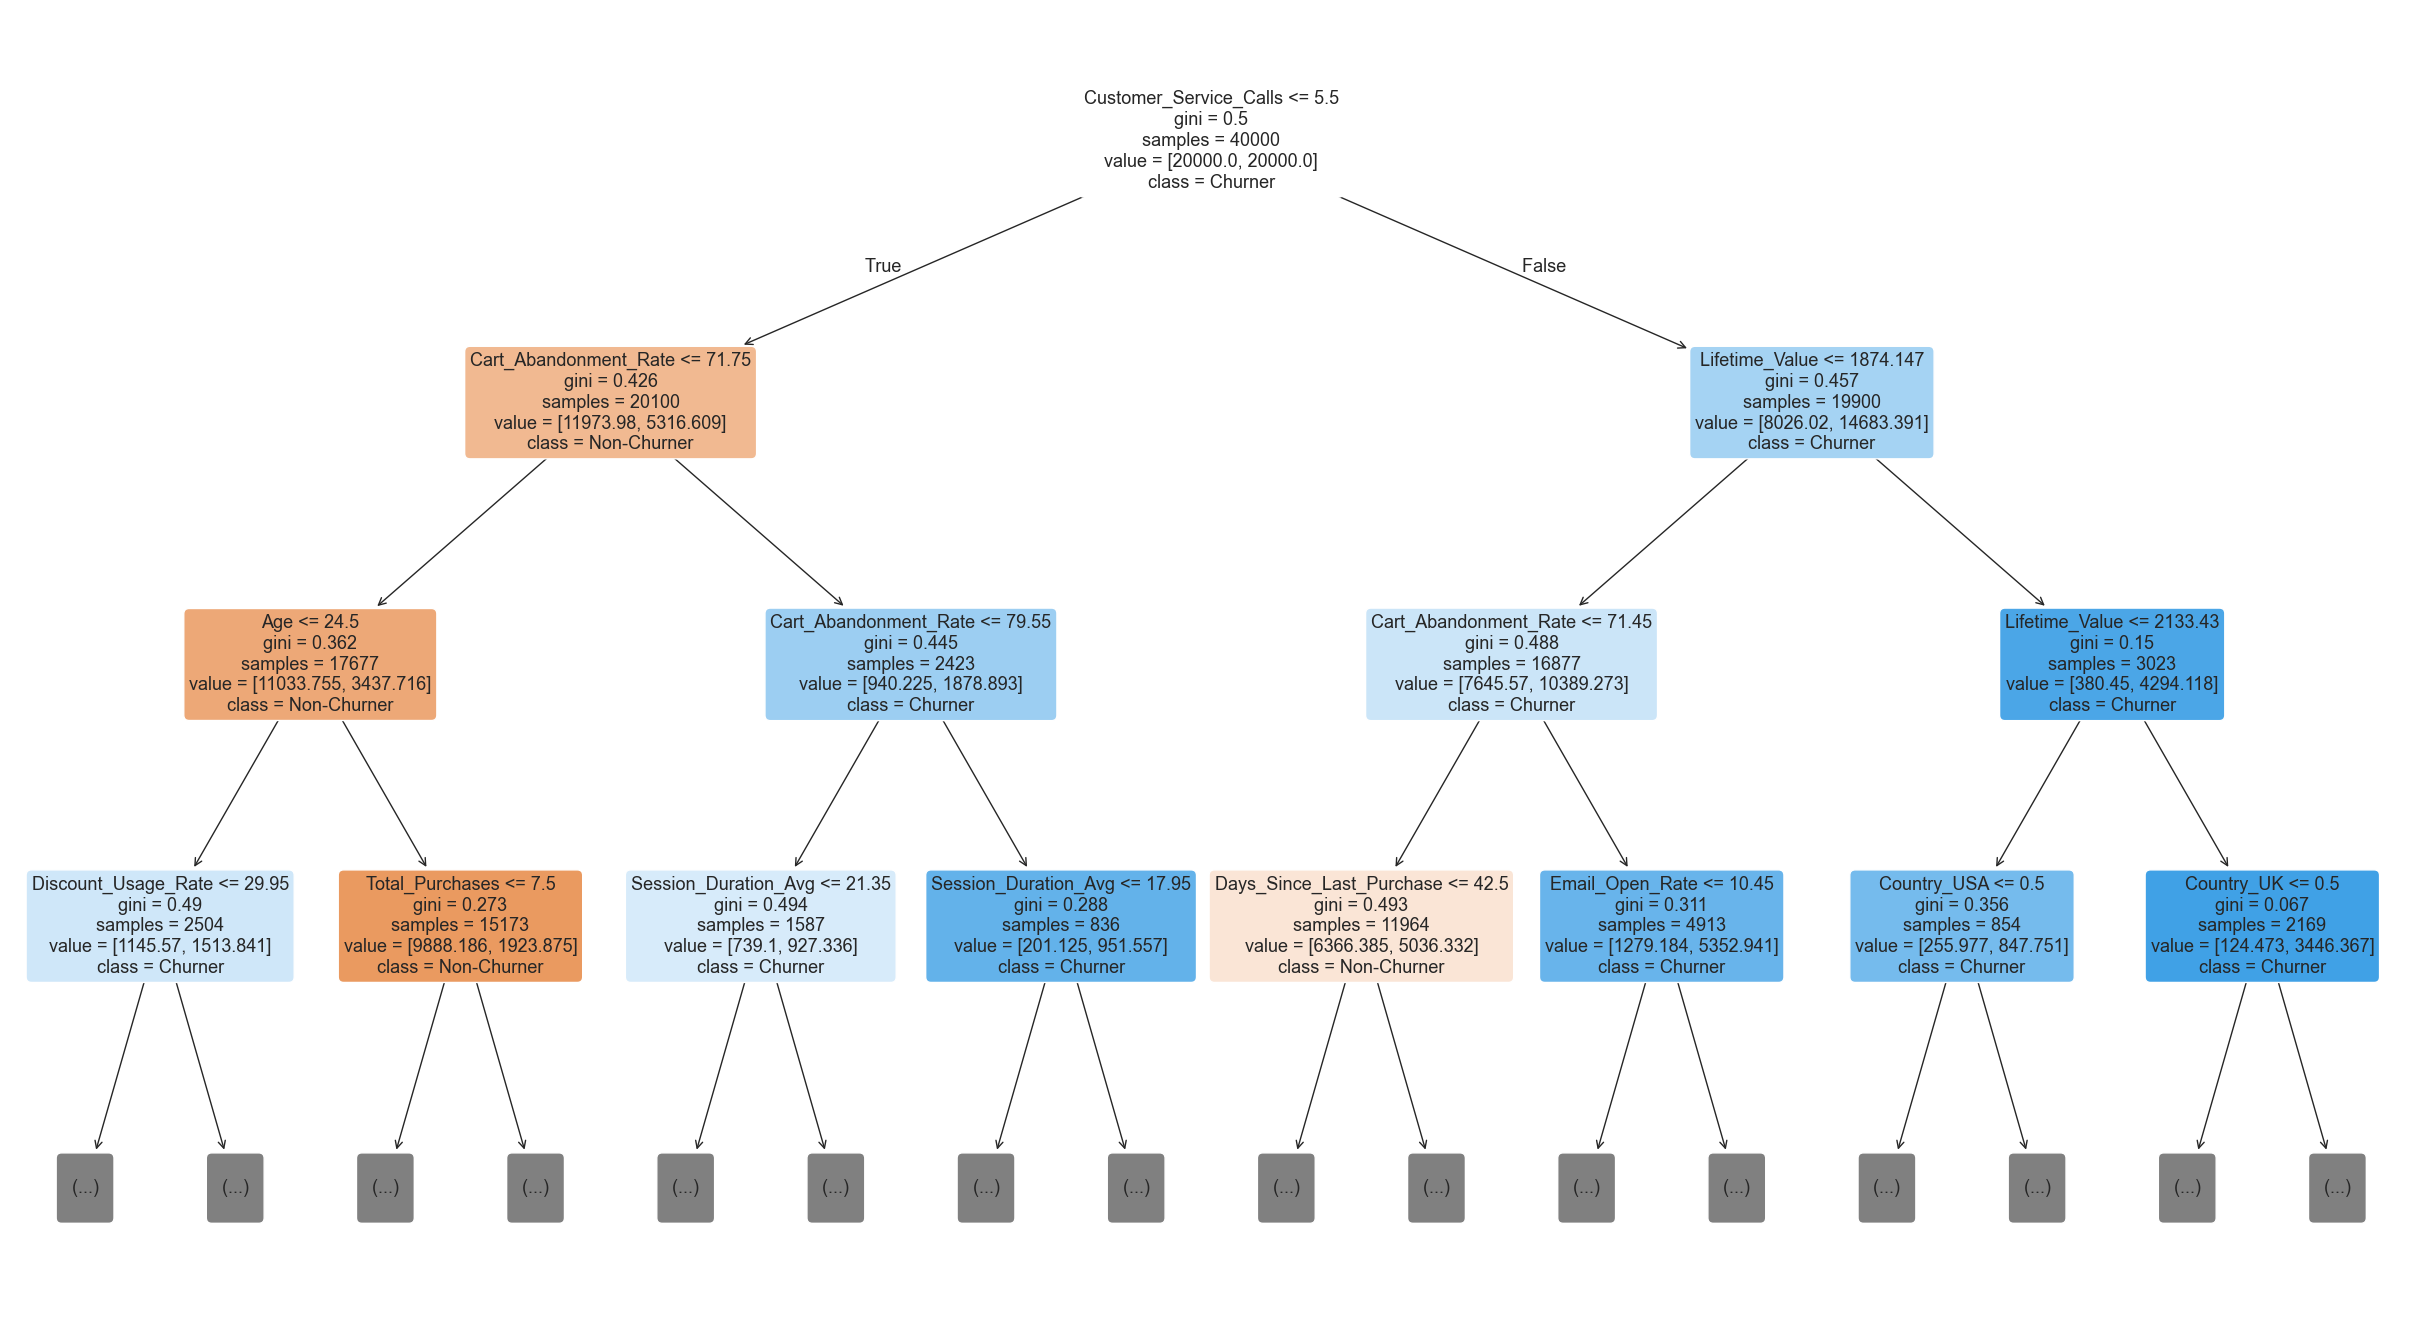

In [226]:
t_feature_names = t_preprocessor.get_feature_names_out()
t_feature_names= [
    name.replace("cat__", "").replace("num__", "")
    for name in t_feature_names
]

plt.figure(figsize=(31, 17))
plot_tree(dtc, feature_names=t_feature_names, class_names=["Non-Churner", "Churner"],
         filled=True, rounded=True, fontsize=13, max_depth=3)

plt.show()

## 8.3 Tree-Based Feature Importance

In [227]:
# to get features before one hot encoding then get aggregate
def get_original_features(feature):
    for col in cat_cols:
        if feature == col or feature.startswith(col + "_"):
            return col
    return feature

In [228]:
def aggregate_tree_importance(model):
    # get transfrm feat names
    feature_names = t_preprocessor.get_feature_names_out()
    model.fit(X_train_t, y_train)
    
    #get importance, perm impo
    importances = model.feature_importances_

    df_importances = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    #remove prefixes
    df_importances["Feature"] = (df_importances["Feature"].str.replace(r"^.*__", "", regex=True))

    #map to original feat
    df_importances["Feature"] = (df_importances["Feature"].apply(get_original_features))
    
    #aggregate ohe features
    df_importances = (df_importances.groupby("Feature", as_index=False)["Importance"]
                     .sum().sort_values("Importance", ascending=False).reset_index(drop=True))

    return df_importances

In [229]:
dt_importance = aggregate_tree_importance(dtc)
rf_importance = aggregate_tree_importance(rfc)
xgb_importance = aggregate_tree_importance(xgbc)

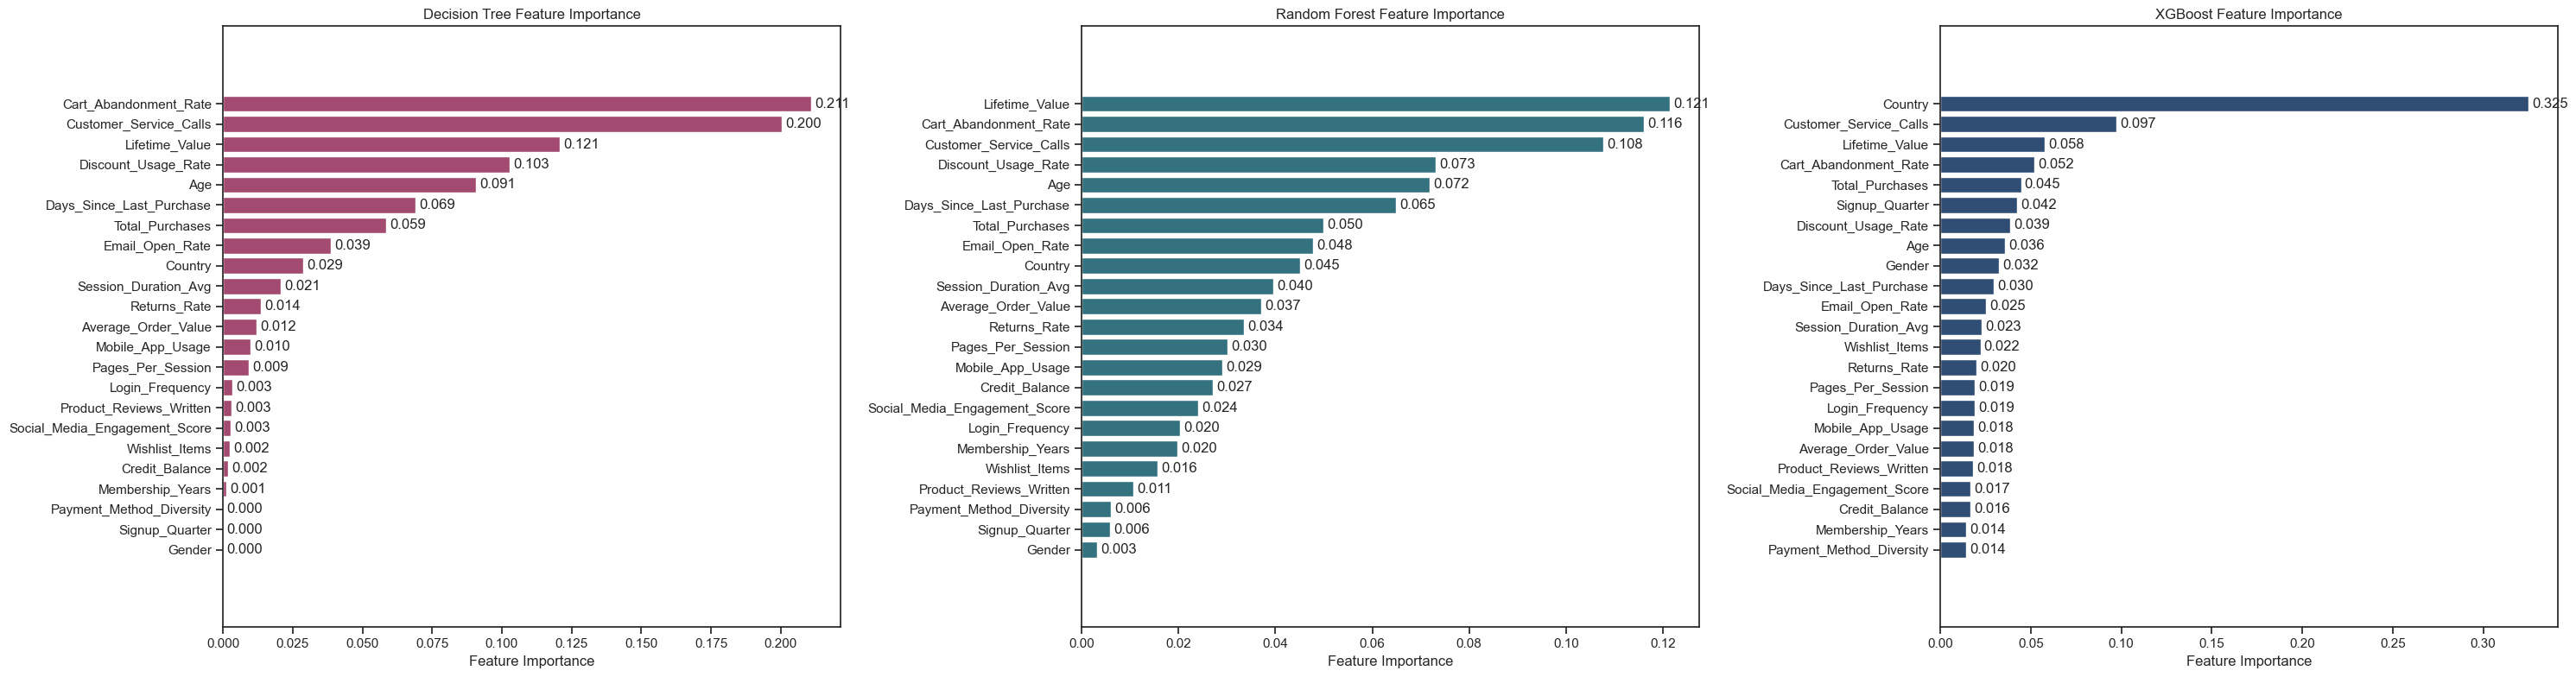

In [230]:
fig, axes = plt.subplots(1, 3, figsize=(30,8))
axes = axes.flatten()

sns.barplot(data=dt_importance, x="Importance", y="Feature",color=palette[3], ax=axes[0])
axes[0].set_title("Decision Tree Feature Importance")
axes[0].set_xlabel("Feature Importance")
axes[0].set_ylabel(None)
axes[0].bar_label(axes[0].containers[0], fmt="%.3f", clip_on=False, padding=3)
axes[0].margins(y=0.15)

sns.barplot(data=rf_importance, x="Importance", y="Feature", color=palette2[3], ax=axes[1])
axes[1].set_title("Random Forest Feature Importance")
axes[1].set_xlabel("Feature Importance")
axes[1].set_ylabel(None)
axes[1].bar_label(axes[1].containers[0], fmt="%.3f", clip_on=False, padding=3)
axes[1].margins(y=0.15)

sns.barplot(data=xgb_importance, x="Importance", y="Feature", color=palette2[5], ax=axes[2])
axes[2].set_title("XGBoost Feature Importance")
axes[2].set_xlabel("Feature Importance")
axes[2].set_ylabel(None)
axes[2].bar_label(axes[2].containers[0], fmt="%.3f", clip_on=False, padding=3)
axes[2].margins(y=0.15)

plt.tight_layout()
plt.show()

In [231]:
df_top5_tree = pd.DataFrame({
    "DT": ["Cart_Abandonment_Rate", "Customer_Service_Calls", "Lifetime_Value", "Discount_Usage_Rate",  "Age"],
    "RF": ["Lifetime_Value", "Cart_Abandonment_Rate", "Customer_Service_Calls", "Age", "Discount_Usage_Rate"],
    "XGB": ["Country", "Customer_Service_Calls", "Lifetime_Value", "Cart_Abandonment_Rate", "Total_Purchases"]
}, index=pd.RangeIndex(1,6))
df_top5_tree

,DT,RF,XGB
1,Cart_Abandonment_Rate,Lifetime_Value,Country
2,Customer_Service_Calls,Cart_Abandonment_Rate,Customer_Service_Calls
3,Lifetime_Value,Customer_Service_Calls,Lifetime_Value
4,Discount_Usage_Rate,Age,Cart_Abandonment_Rate
5,Age,Discount_Usage_Rate,Total_Purchases


---
# 9. GLOBAL SHAP EXPLANATIONS
Bar plot ranks features by their mean absolute shap value (overall importance)\
Beeswarm plot shows the importance and direction of each feature -> whether it tends to increase or decrease predicted probability of churn

Each dot of the beeswarm plot represents a single customer. The x axis shows the impact on the model output (right pushes towards churn, left pushes towards non-churn). Colour shows the feature value (red is high, blue is low). They're ordered by overall importance

## 9.1 Logistic Regression Explanations

In [232]:
lr_explainer = shap.LinearExplainer(lrc, X_test_lr)
lr_shap_values = lr_explainer(X_test_lr)
lr_shap_values.feature_names = lr_feature_names

Background dataset has 10000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10000 when initializing the masker.


Text(0.5, 1.0, 'Logistic Regression Global SHAP Feature Importance')

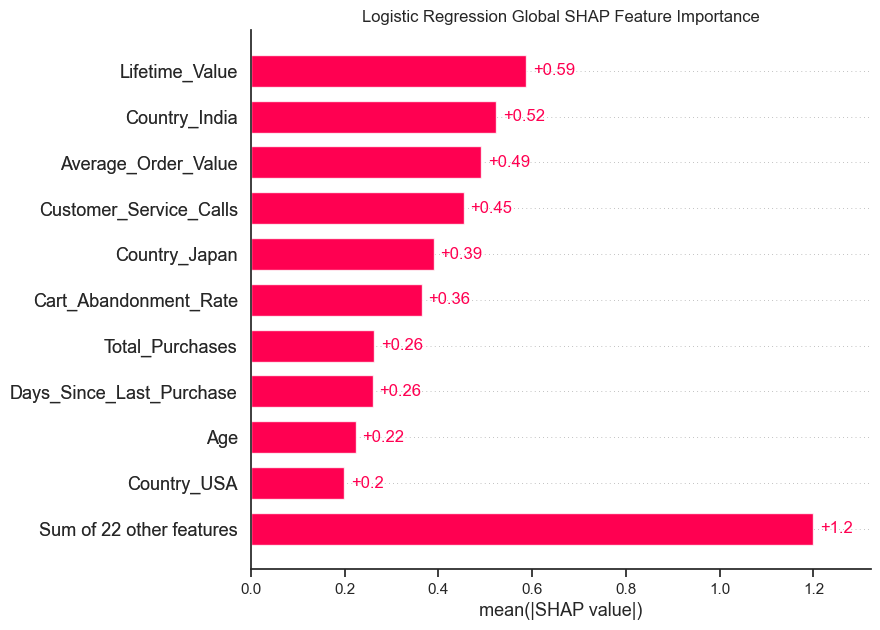

In [233]:
shap.plots.bar(lr_shap_values.abs.mean(0), max_display=11, show=False)
plt.title("Logistic Regression Global SHAP Feature Importance")

Text(0.5, 1.0, 'Logistic Regression Global SHAP Feature Importance')

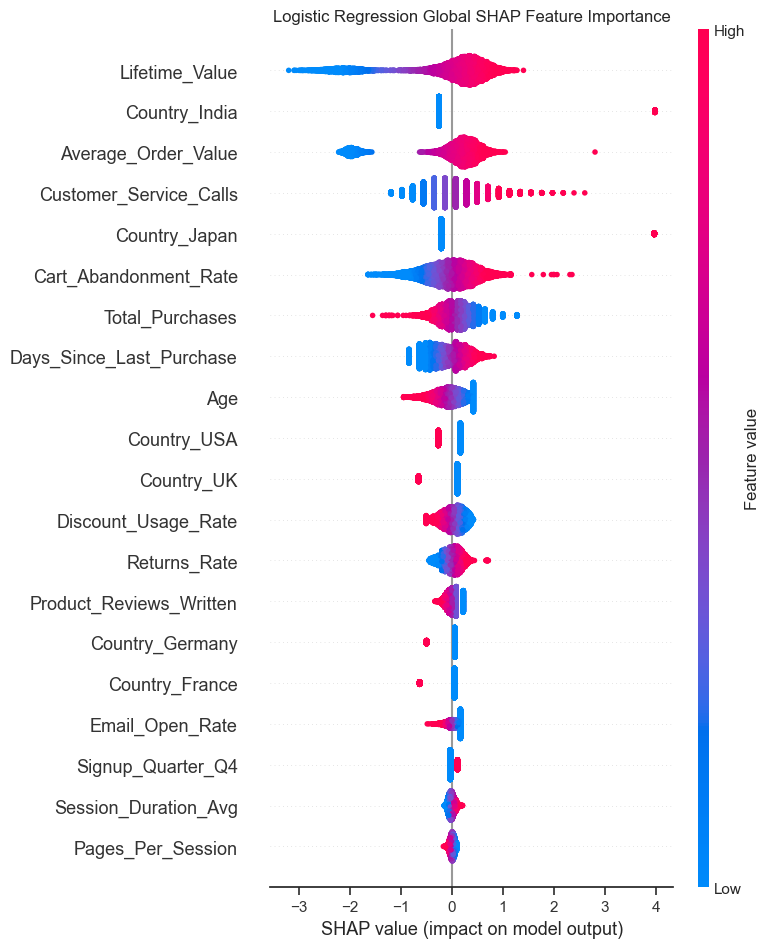

In [234]:
lr_shap_numeric = np.asarray(lr_shap_values.values, dtype=float) #conv to num
shap.summary_plot(lr_shap_numeric, X_test_lr, feature_names = lr_feature_names, show=False)
plt.title("Logistic Regression Global SHAP Feature Importance")

## 9.2 Decision Tree Explanations

In [235]:
t_feature_names = t_preprocessor.get_feature_names_out()
t_feature_names= [
    name.replace("cat__", "").replace("num__", "").replace("log__", "")
    for name in t_feature_names
]

In [236]:
dt_explainer = shap.TreeExplainer(dtc, feature_perturbation="tree_path_dependent")
dt_shap_values = dt_explainer(X_test_t)
dt_shap_values.feature_names = t_feature_names

dt_shap_churn = dt_shap_values[:,:,1] # for churned = 1

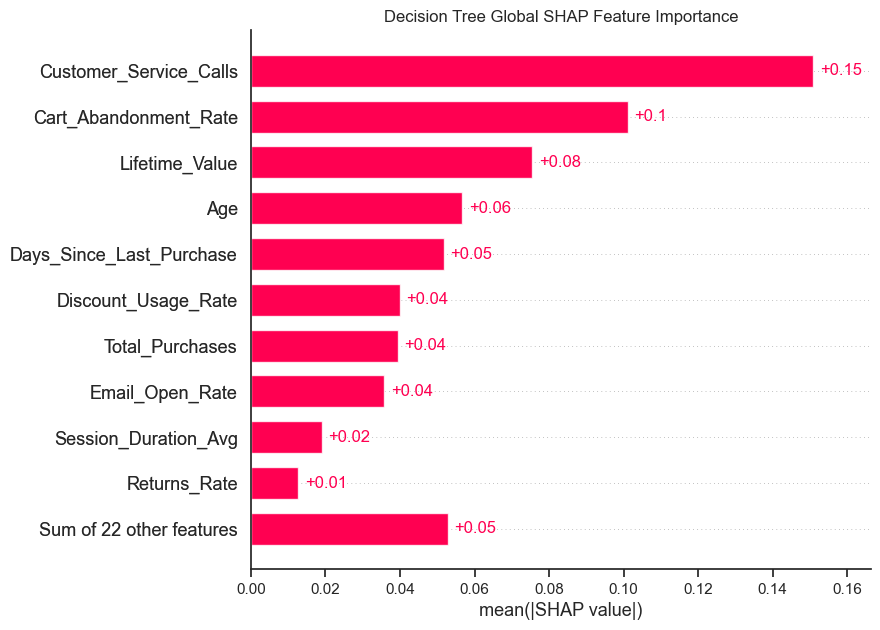

In [237]:
shap.plots.bar(dt_shap_churn.abs.mean(0), max_display=11, show=False) # for churned = 1
plt.title("Decision Tree Global SHAP Feature Importance")
plt.show()

Text(0.5, 1.0, 'Decision Tree Global SHAP Feature Importance')

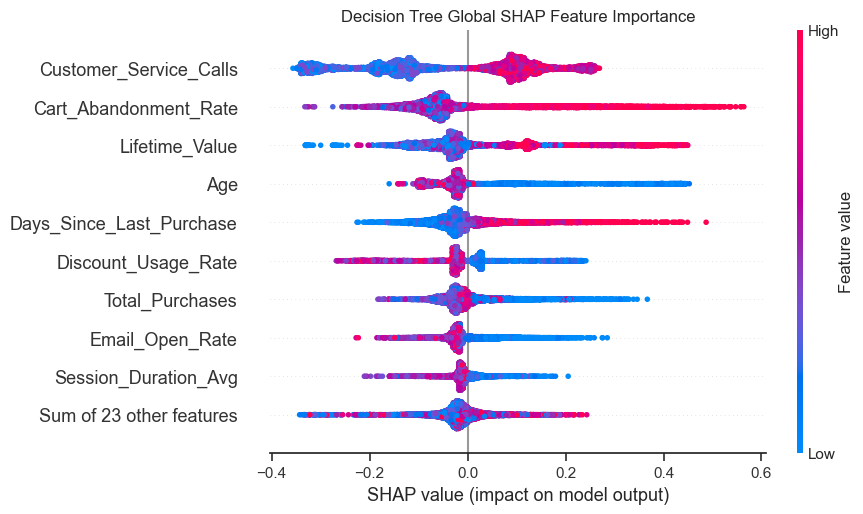

In [238]:
shap.plots.beeswarm(dt_shap_churn, show=False)
plt.title("Decision Tree Global SHAP Feature Importance")

## 9.3 Random Forest Explanations

In [239]:
rf_explainer = shap.TreeExplainer(rfc, feature_perturbation="tree_path_dependent")
rf_shap_values = rf_explainer(X_test_t)
rf_shap_values.feature_names = t_feature_names

rf_shap_churn = rf_shap_values[:,:,1] # for churned = 1

Text(0.5, 1.0, 'Random Forest Global SHAP Feature Importance')

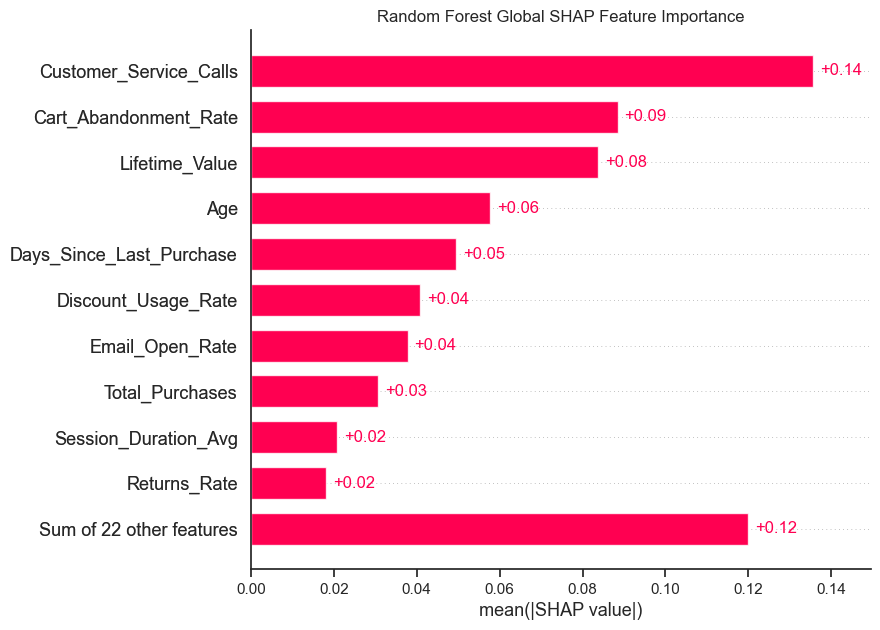

In [240]:
shap.plots.bar(rf_shap_churn.abs.mean(0), max_display=11, show=False) # for churned = 1
plt.title("Random Forest Global SHAP Feature Importance")

Text(0.5, 1.0, 'Random Forest Global SHAP Feature Importance')

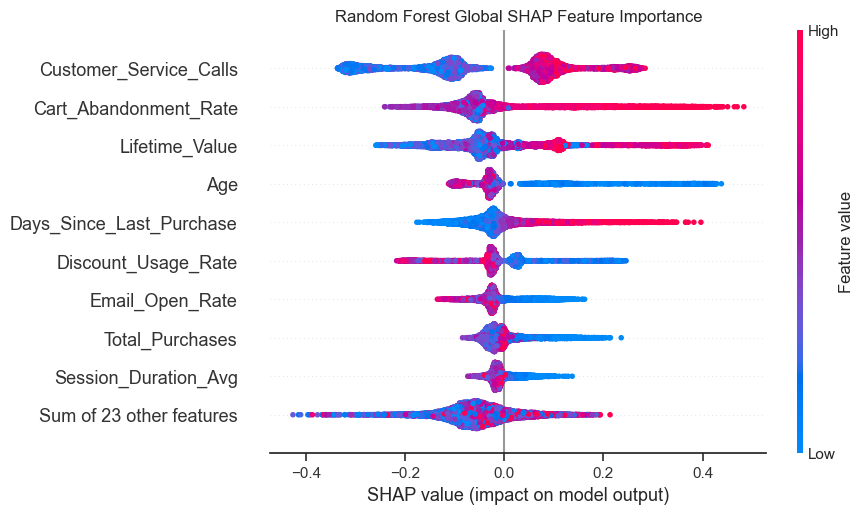

In [241]:
shap.plots.beeswarm(rf_shap_churn, show=False)
plt.title("Random Forest Global SHAP Feature Importance")

## 9.4 XGBoost Explanations

In [242]:
xgb_explainer = shap.Explainer(xgbc, feature_perturbation="tree_path_dependent")
xgb_shap_values = xgb_explainer(X_test_t)
xgb_shap_values.feature_names = t_feature_names

#xgb_shap_churn = xgb_shap_values[:,:,1] # for churned = 1
#xgb_shap_nonchurn = xgb_shap_values[:,:,0] # for churned = 0

Text(0.5, 1.0, 'XGBoost Global SHAP Feature Importance')

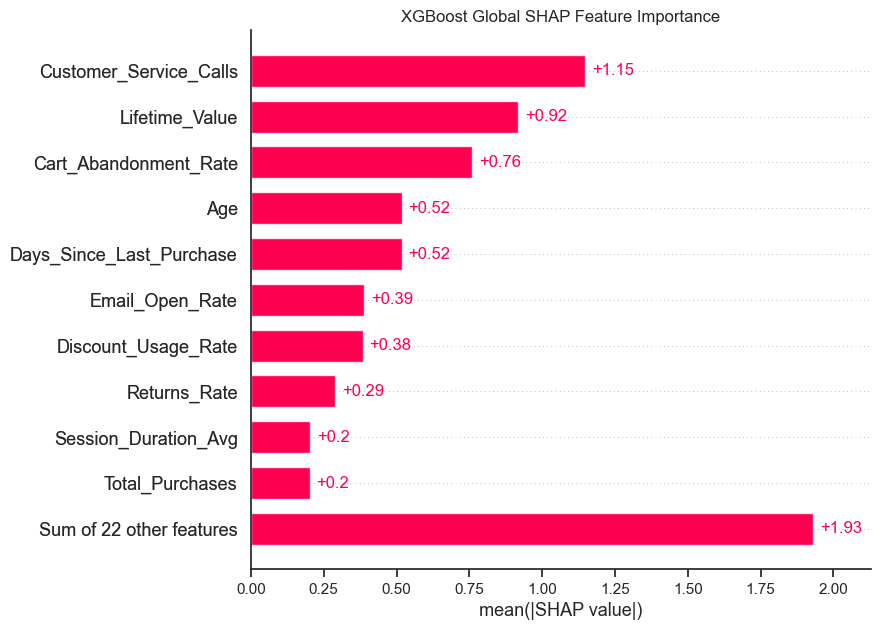

In [243]:
shap.plots.bar(xgb_shap_values.abs.mean(0), max_display=11, show=False) # for churned = 1
plt.title("XGBoost Global SHAP Feature Importance")

Text(0.5, 1.0, 'XGBoost Global SHAP Feature Importance')

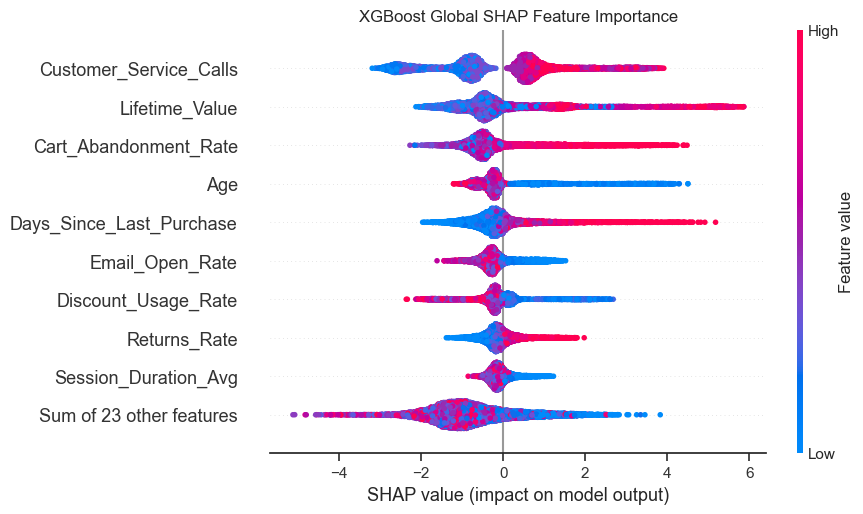

In [244]:
shap.plots.beeswarm(xgb_shap_values, show=False)
plt.title("XGBoost Global SHAP Feature Importance")

# 10. LOCAL SHAP EXPLANATIONS
Comparisons of features contributing to individual predictions\
Local SHAP explanations from the same correctly classified churn and non-churn test observations for all four models (I arbitrarily chose the 23rd prediction made by each model)

In [245]:
#correct predictions aligned to y_test
correct_all = (
    (lr_pred == y_test) & (dt_pred == y_test) & (rf_pred == y_test) & (rf_pred == y_test)
)

# positions where they are ALL correct
churn_pos = np.where(correct_all & (y_test.values == 1))[0]
nonchurn_pos = np.where(correct_all & (y_test.values == 0))[0]

churn_i = churn_pos[23]
nonchurn_i = nonchurn_pos[23]

## 10.1 Logistic Regression

In [246]:
# values scaled and transformed so i need to map them to the original values
X_test_lr_display = pd.DataFrame(
    X_test_lr, columns=lr_feature_names, index=X_test_imputed.index
)
# replace transformed features with their original values
for col in normal_num_cols:
    X_test_lr_display[col] = X_test_imputed[col]

for col in skewed_cols:
    X_test_lr_display[col] = X_test_imputed[col]

# SHAP explanation
lr_explainer2 = shap.LinearExplainer(lrc, X_test_lr)
lr_shap_values2 = lr_explainer2(X_test_lr)

lr_shap_values2.feature_names = lr_feature_names

# shap explanation for display only
lr_shap_display = shap.Explanation(
    values=lr_shap_values2.values,
    base_values=lr_shap_values2.base_values,
    data=X_test_lr_display.values,
    feature_names=lr_feature_names
)

Background dataset has 10000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10000 when initializing the masker.


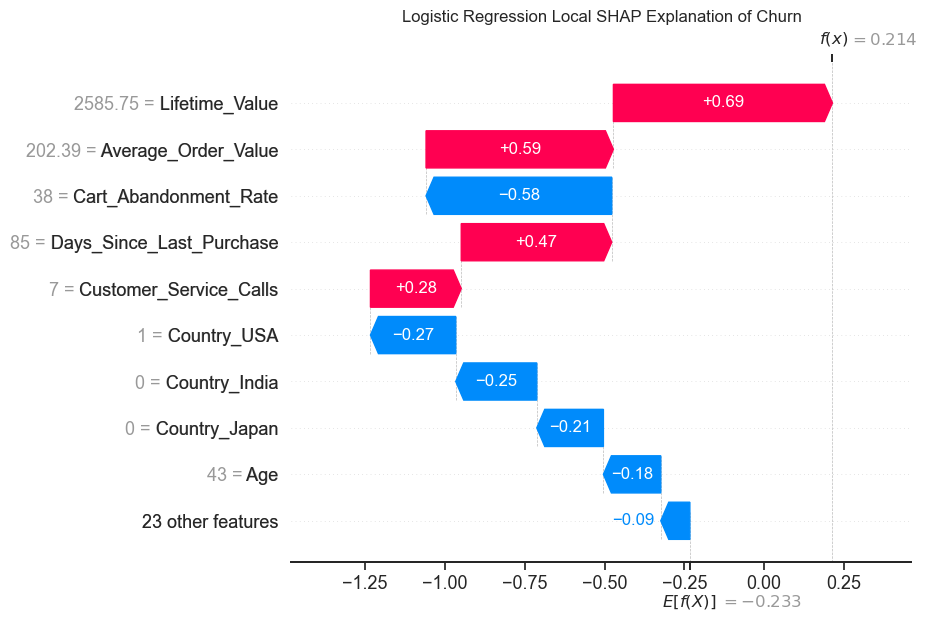

In [247]:
shap.plots.waterfall(lr_shap_display[churn_i], show=False)
plt.title("Logistic Regression Local SHAP Explanation of Churn")
plt.show()

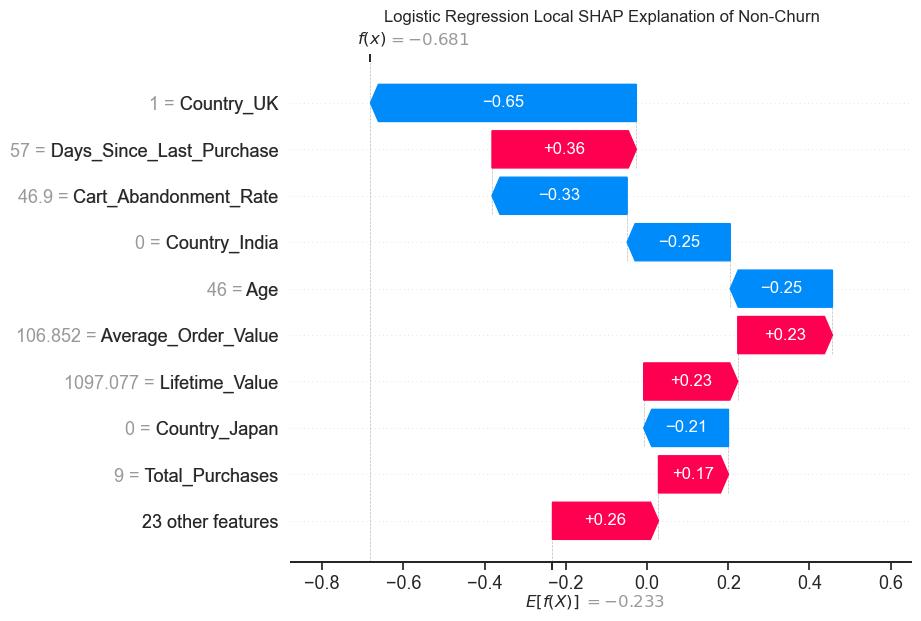

In [248]:
shap.plots.waterfall(lr_shap_display[nonchurn_i], show=False)
plt.title("Logistic Regression Local SHAP Explanation of Non-Churn")
plt.show()

## 10.2 Decision Tree

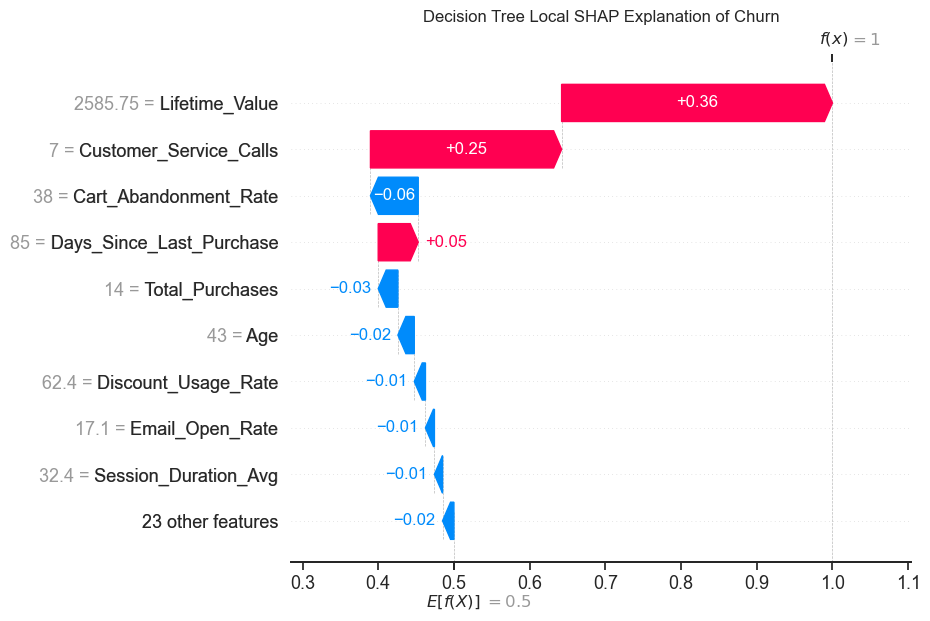

In [249]:
shap.plots.waterfall(dt_shap_values[churn_i, :, 1], show=False)
plt.title("Decision Tree Local SHAP Explanation of Churn")
plt.show()

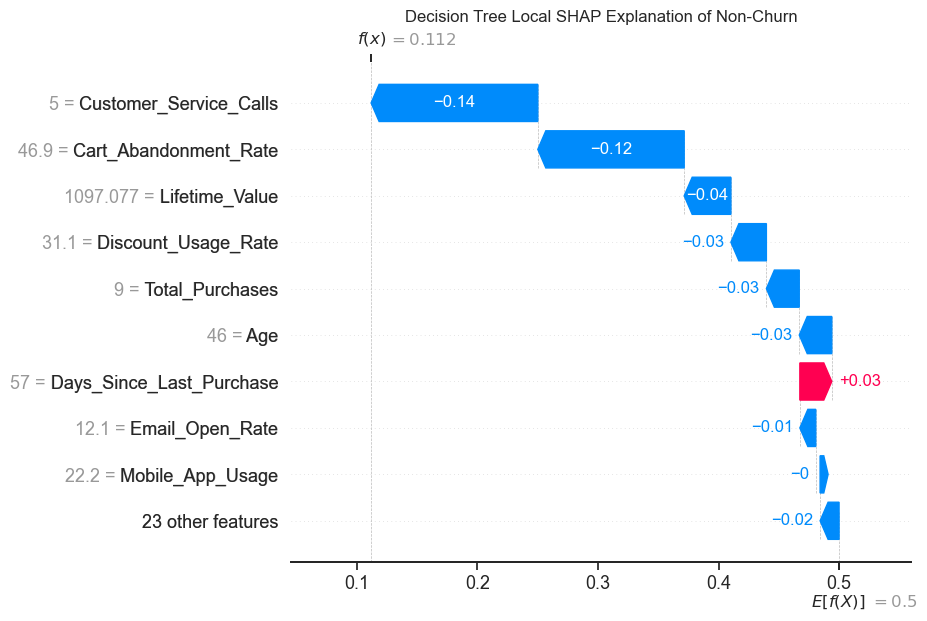

In [250]:
shap.plots.waterfall(dt_shap_values[nonchurn_i, :, 1], show=False)
plt.title("Decision Tree Local SHAP Explanation of Non-Churn")
plt.show()

## 10.3 Random Forest

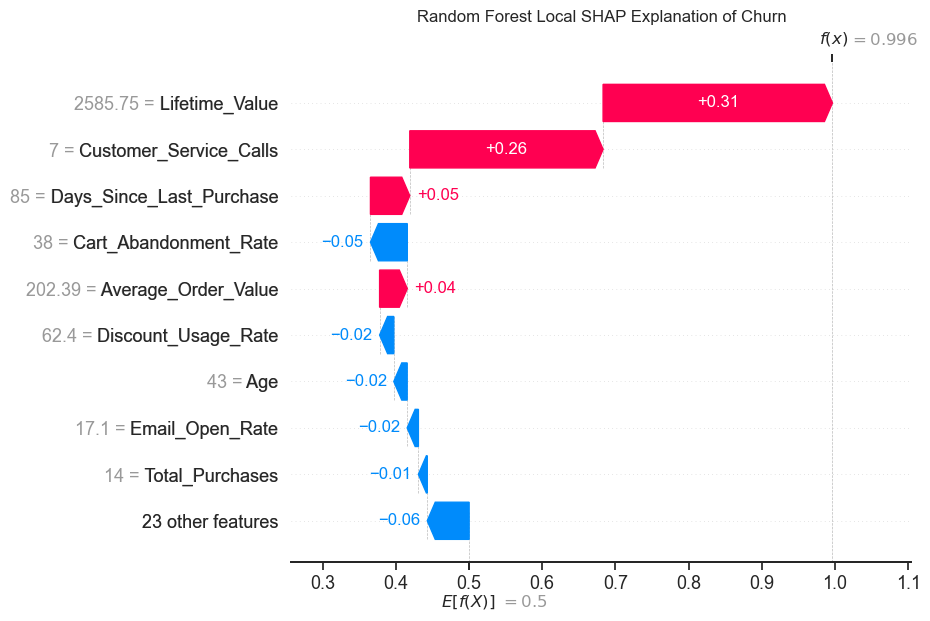

In [251]:
shap.plots.waterfall(rf_shap_values[churn_i, :, 1], show=False)
plt.title("Random Forest Local SHAP Explanation of Churn")
plt.show()

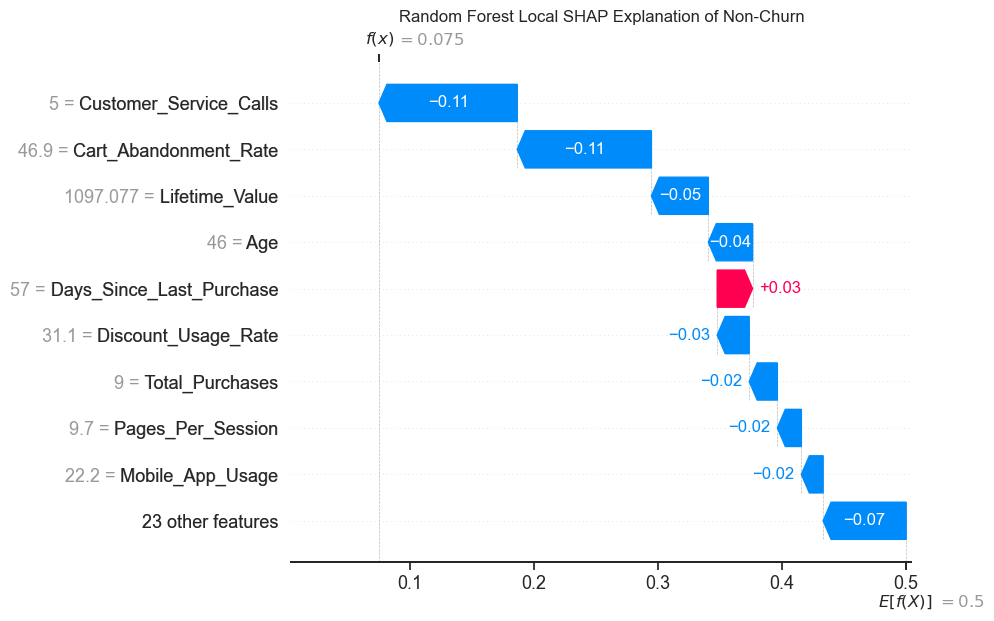

In [252]:
shap.plots.waterfall(rf_shap_values[nonchurn_i, :, 1], show=False)
plt.title("Random Forest Local SHAP Explanation of Non-Churn")
plt.show()

## 10.4 XGBoost

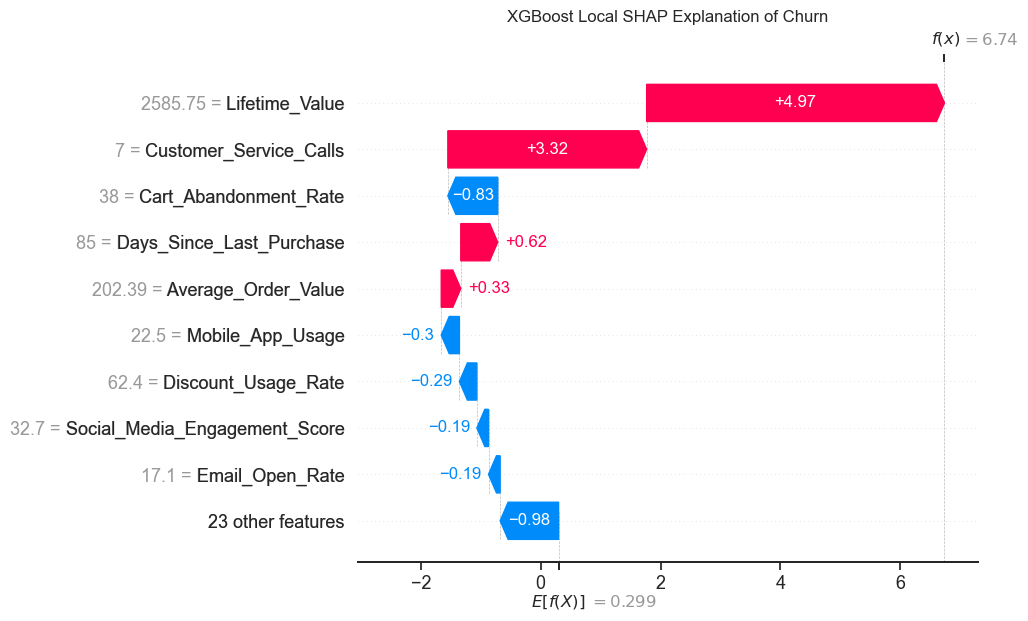

In [253]:
shap.plots.waterfall(xgb_shap_values[churn_i], show=False)
plt.title("XGBoost Local SHAP Explanation of Churn")
plt.show()

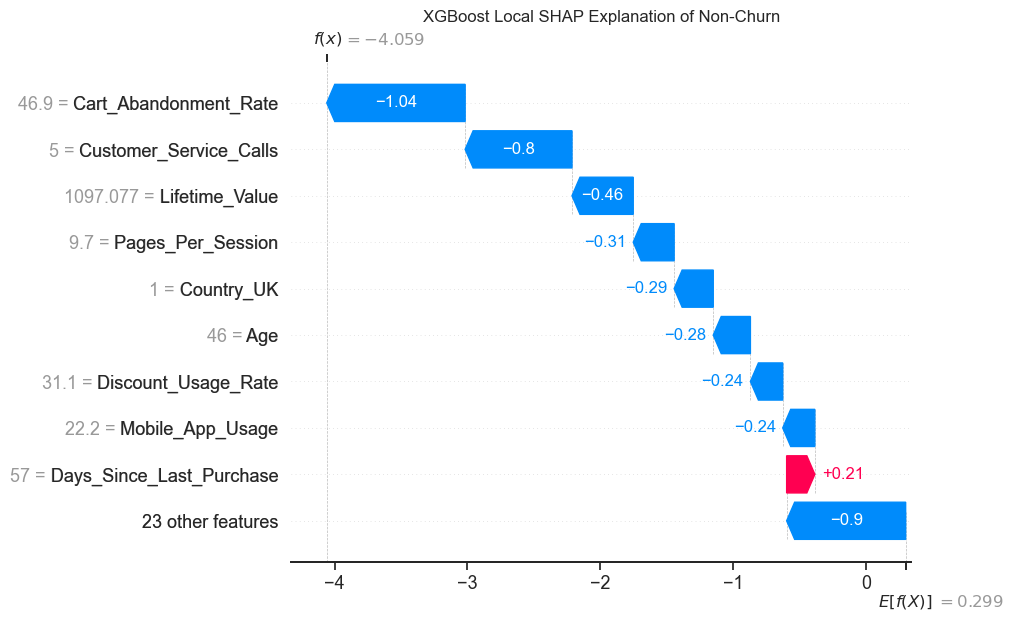

In [254]:
shap.plots.waterfall(xgb_shap_values[nonchurn_i], show=False)
plt.title("XGBoost Local SHAP Explanation of Non-Churn")
plt.show()

## 10.5 Model Confidence (from waterfall plots)

In [256]:
def to_prob(fx, is_log_odds):
    return 1 / (1 + np.exp(-fx)) if is_log_odds else fx

df_conf = pd.DataFrame({
    "Model": ["LR", "DT", "RF", "XGB"],
    "Output scale": ["log-odds", "probability", "probability", "log-odds"],
    "Churner f(x)": [0.932, 0.844, 0.956, 5.543],
    "Non-churner f(x)": [-1.241, 0.353, 0.146, -2.461],
}).set_index("Model")

is_lo = df_conf["Output scale"] == "log-odds"

df_conf["Churner confidence"] = [
    to_prob(fx, lo) for fx, lo in zip(df_conf["Churner f(x)" ], is_lo)
]
df_conf["Non-churner P(churn)"] = [
    to_prob(fx, lo) for fx, lo in zip(df_conf["Non-churner f(x)"], is_lo)
]
df_conf["Non-churner confidence"] = 1 - df_conf["Non-churner P(churn)"]


In [257]:
df_conf.index.name=None
df_conf

,Output scale,Churner f(x),Non-churner f(x),Churner confidence,Non-churner P(churn),Non-churner confidence
LR,log-odds,0.932,-1.241,0.717481,0.224262,0.775738
DT,probability,0.844,0.353,0.844000,0.353000,0.647000
RF,probability,0.956,0.146,0.956000,0.146000,0.854000
XGB,log-odds,5.543,-2.461,0.996101,0.078638,0.921362


# 11. MISCELLANEOUS

## 11.1 Linearity
Binned log-odds plots for continuous numerical features

In [258]:
cont_cols = ["Age", 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 
             'Average_Order_Value', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Mobile_App_Usage','Lifetime_Value', 'Credit_Balance']


In [259]:
# Use training data only
diag_df = X_train_imputed[cont_cols].copy()

# Convert target to 0/1
y_diag = y_train.copy()

if y_diag.dtype == "object":
    y_diag = y_diag.map({"No": 0, "Yes": 1})

diag_df["Churn"] = y_diag.astype(int).to_numpy()

# Apply the same log1p transformation used in your preprocessor
for col in skewed_cols:
    if col in cont_cols:
        diag_df[col] = np.log1p(diag_df[col])


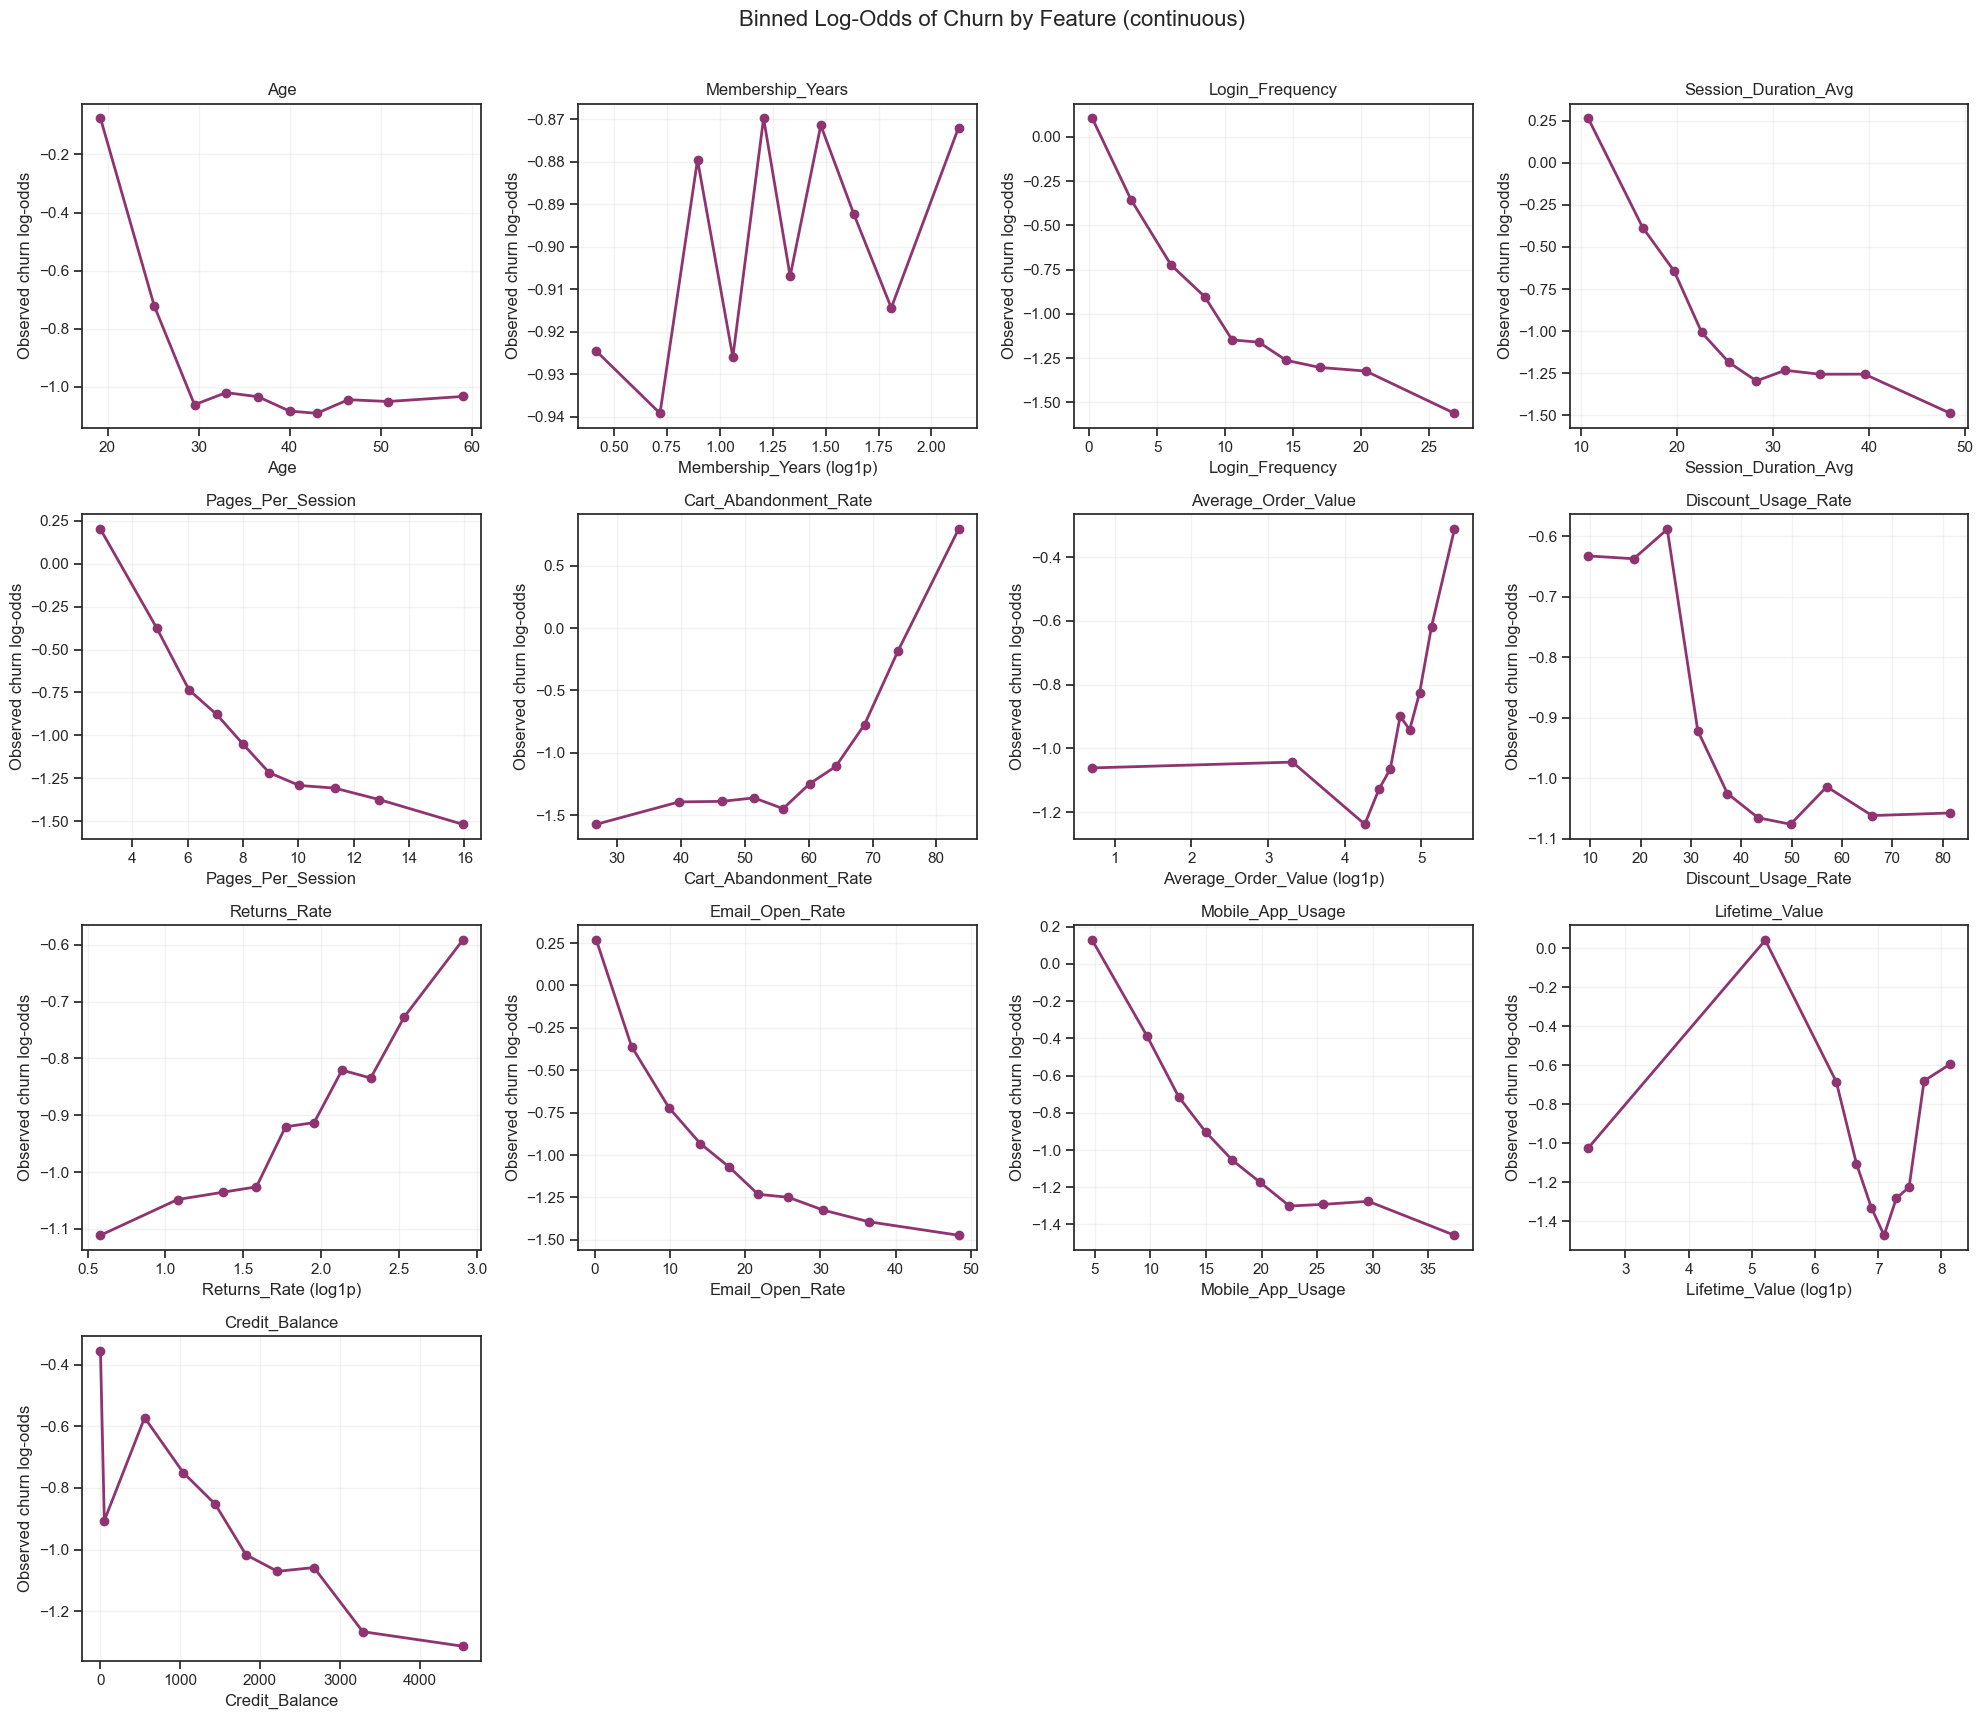

In [260]:
# Plot all features
fig, axes = plt.subplots(4, 4, figsize=(20, 17))
axes = axes.flatten()

for i, col in enumerate(cont_cols):
    ax = axes[i]

    # Divide into up to 10 quantile bins
    bins = pd.qcut( diag_df[col], q=10, duplicates="drop")

    grouped = diag_df.groupby(bins, observed=True)["Churn"].agg(["mean", "count", "sum"])

    # avg feature value in each bin
    grouped["x_mean"] = [diag_df.loc[bins == interval, col].mean() for interval in grouped.index ]

    # smoothed empirical log-odds
    churn = grouped["sum"]
    non_churn = grouped["count"] - churn

    grouped["log_odds"] = np.log((churn + 0.5) / (non_churn + 0.5))

    ax.plot(grouped["x_mean"], grouped["log_odds"], marker="o", linewidth=2, color=palette[4])

    ax.set_title(col)
    ax.set_xlabel( f"{col} (log1p)" if col in skewed_cols else col)
    ax.set_ylabel("Observed churn log-odds")
    ax.grid(alpha=0.25)

# Hide unused subplot
for j in range(len(cont_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Binned Log-Odds of Churn by Feature (continuous)", fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

## 11.2 Other Local SHAP predictions
(From XGB)

### 11.2.1 Churners

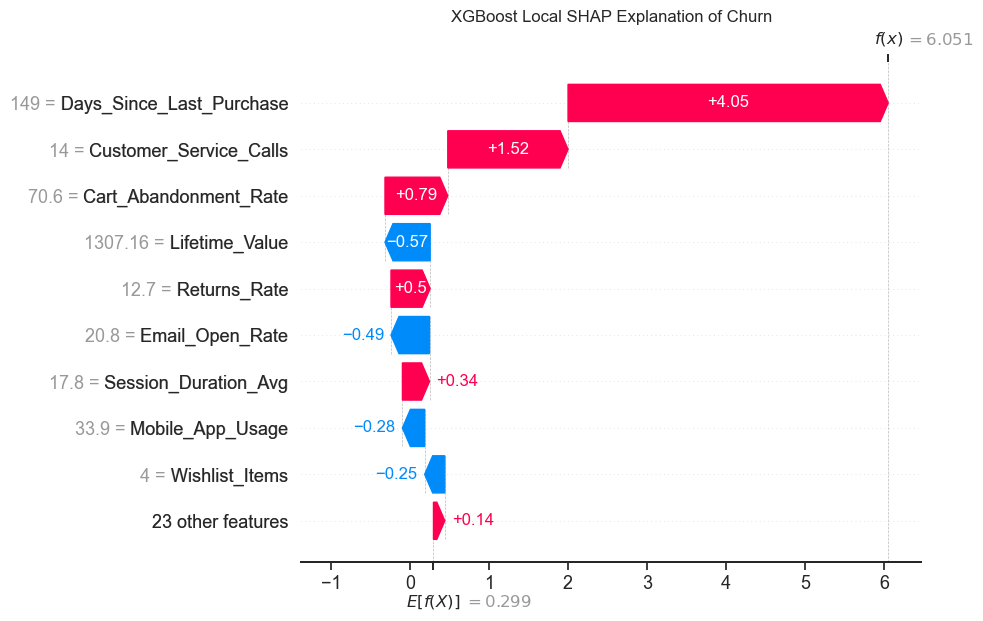

In [261]:
shap.plots.waterfall(xgb_shap_values[churn_pos[100]], show=False)
plt.title("XGBoost Local SHAP Explanation of Churn")
plt.show()

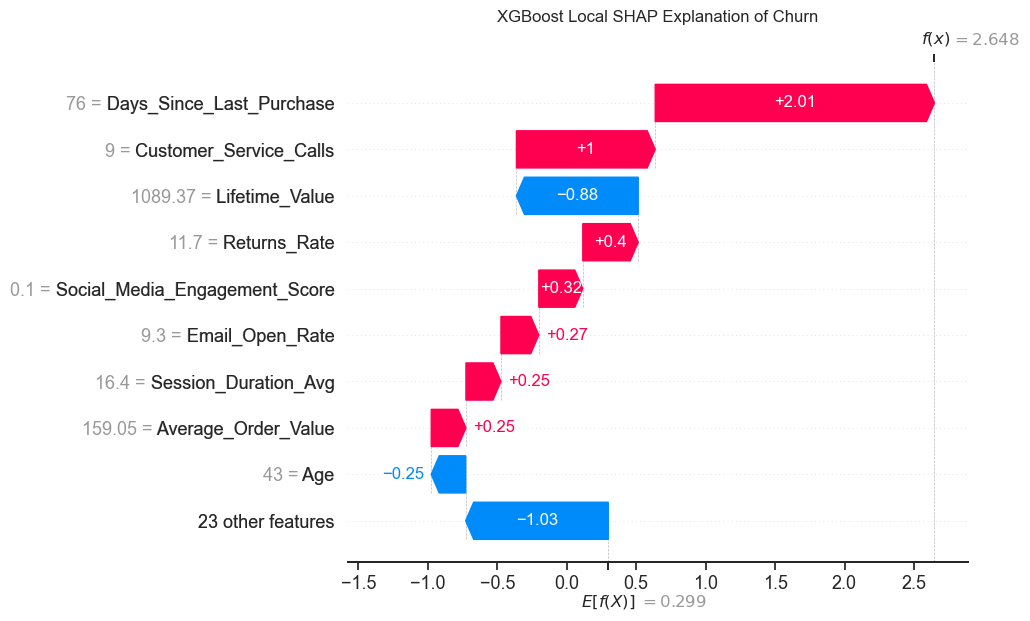

In [262]:
shap.plots.waterfall(xgb_shap_values[churn_pos[50]], show=False)
plt.title("XGBoost Local SHAP Explanation of Churn")
plt.show()

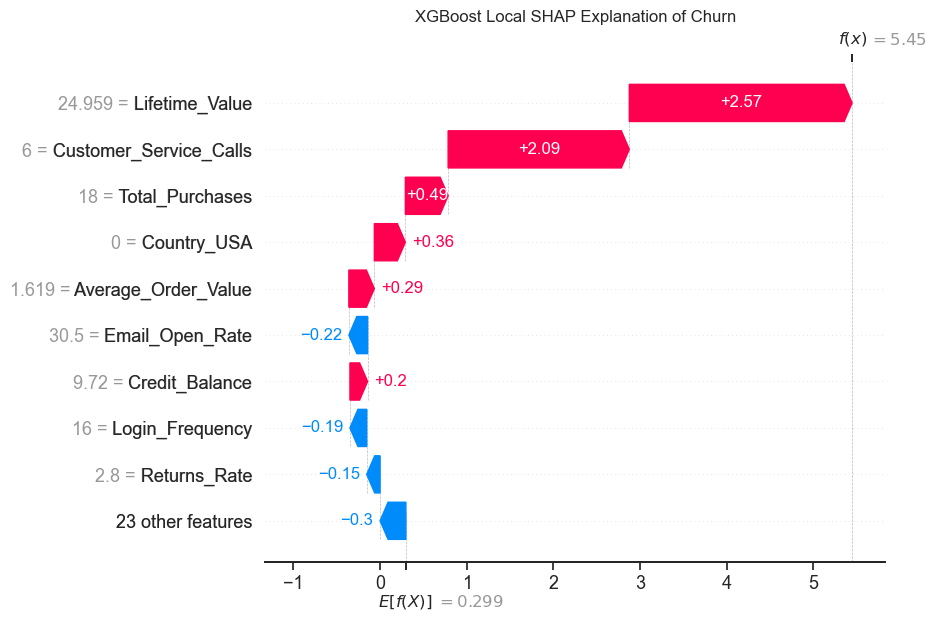

In [263]:
shap.plots.waterfall(xgb_shap_values[churn_pos[1]], show=False)
plt.title("XGBoost Local SHAP Explanation of Churn")
plt.show()

### 11.2.2 Non-Churners

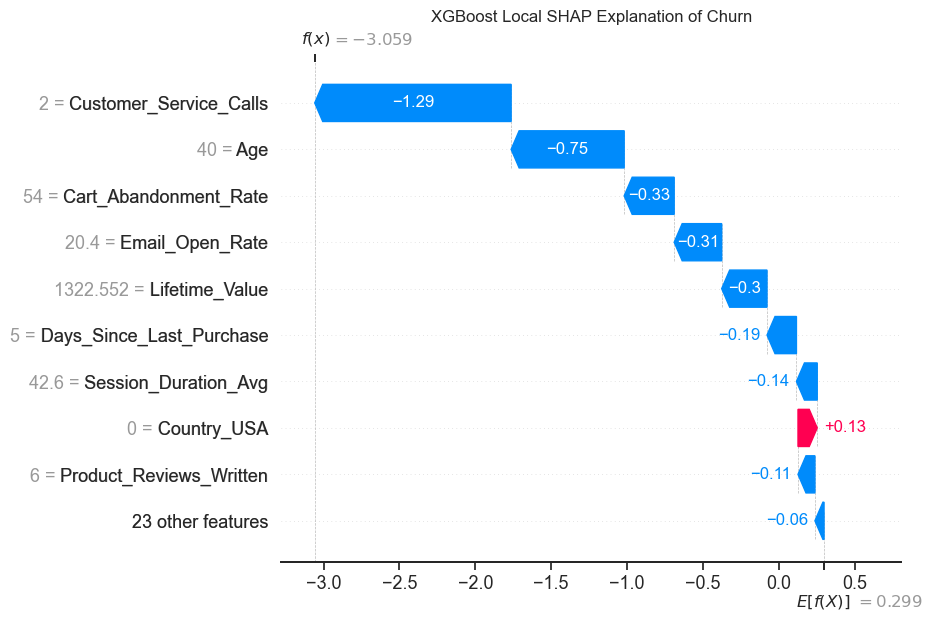

In [264]:
shap.plots.waterfall(xgb_shap_values[nonchurn_pos[100]], show=False)
plt.title("XGBoost Local SHAP Explanation of Churn")
plt.show()

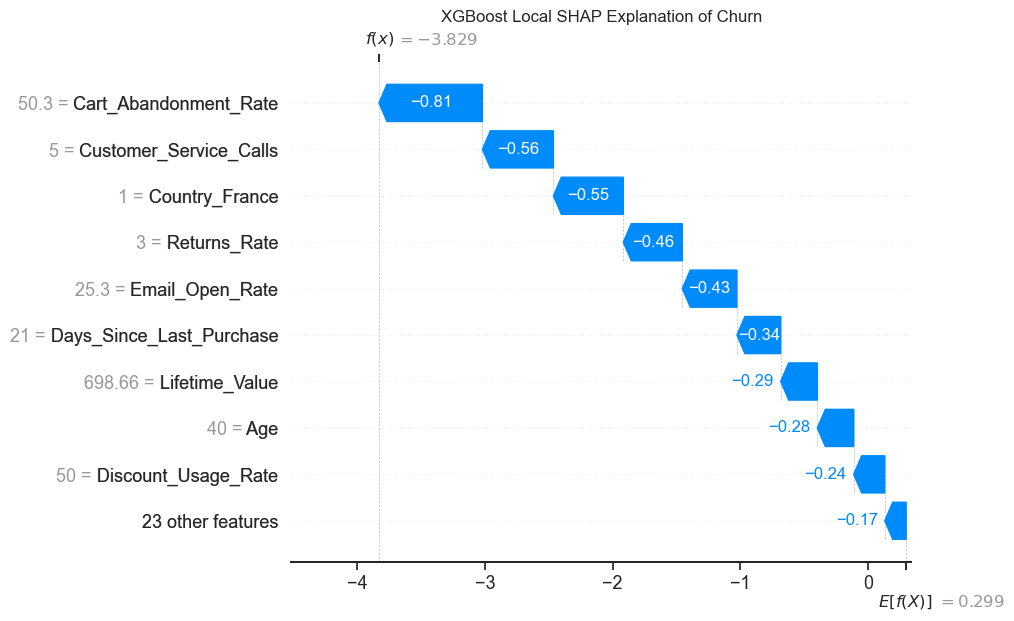

In [265]:
shap.plots.waterfall(xgb_shap_values[nonchurn_pos[50]], show=False)
plt.title("XGBoost Local SHAP Explanation of Churn")
plt.show()

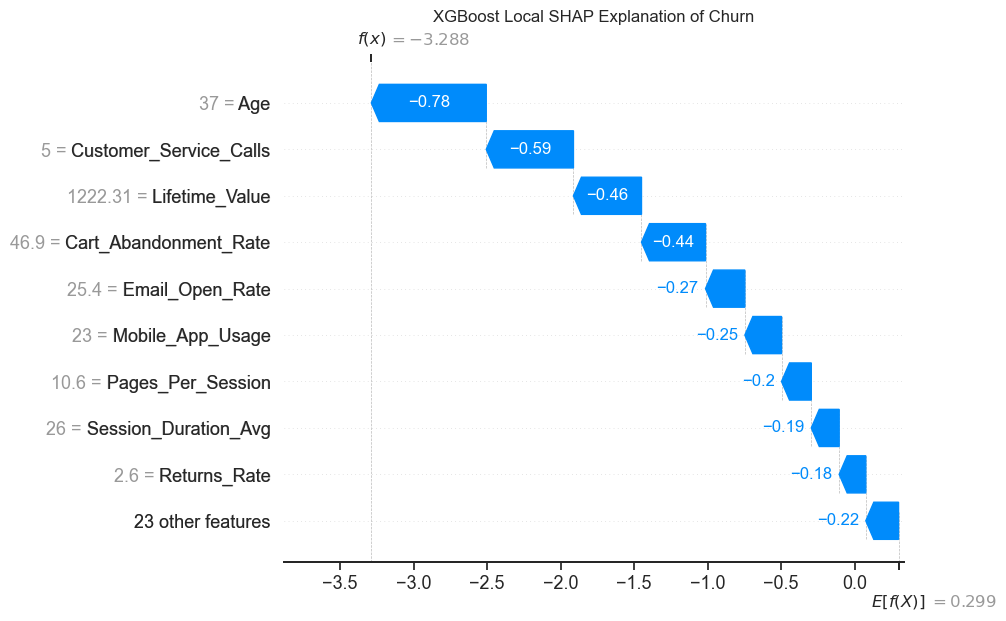

In [266]:
shap.plots.waterfall(xgb_shap_values[nonchurn_pos[1]], show=False)
plt.title("XGBoost Local SHAP Explanation of Churn")
plt.show()